In [2]:
import dask
import hest
print(hest.__version__)
from hest.HESTData import read_HESTData
from hest import iter_hest
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd
import math

import scanpy as sc

# cutomised function
from hest.patching_wrapper import *

0.0.1


In [3]:
hest_root = "/project/simmons_hts/kxu/hest/data"

# Dump patches for all samples automatically
#patch_hest_samples(hest_root)

# Or only for specific samples
sample_ids = ["XeniumPR1S1ROI8"]
patch_hest_samples(hest_root, ids=sample_ids)

[WARN] Skipping XeniumPR1S1ROI8: folder does not exist at /project/simmons_hts/kxu/hest/data/XeniumPR1S1ROI8


## Count patches

In [5]:
# Path to your patch file
h5_file_path = (Path(hest_root) / 'patches' / 'XeniumPR1S1ROI2.h5')

with h5py.File(h5_file_path, "r") as f:
    print("HEST patch .h5 structure with shapes:")
    
    def print_h5_structure(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"{name} -> {type(obj)}, shape={obj.shape}, dtype={obj.dtype}")
        else:
            print(f"{name} -> {type(obj)}")

    f.visititems(print_h5_structure)

HEST patch .h5 structure with shapes:
barcode -> <class 'h5py._hl.dataset.Dataset'>, shape=(482, 1), dtype=object
coords -> <class 'h5py._hl.dataset.Dataset'>, shape=(482, 2), dtype=int64
img -> <class 'h5py._hl.dataset.Dataset'>, shape=(482, 224, 224, 3), dtype=uint8


In [6]:
def count_patches(patches_dir):
    """
    Count patches per sample, print total, and save results as CSV.

    Args:
        patches_dir (str or Path): folder containing .h5 patch files
        csv_path (str or Path): path to save CSV file
    Returns:
        pandas.DataFrame
    """
    patches_dir = Path(patches_dir)
    results = []

    for h5_file in patches_dir.glob("*.h5"):
        sample_id = h5_file.stem
        with h5py.File(h5_file, "r") as f:
            num_patches = f["img"].shape[0]
        results.append({"sample_id": sample_id, "num_patches": num_patches})

    df = pd.DataFrame(results)
    total_patches = df["num_patches"].sum()

    print(df)
    print(f"\nTotal patches across all samples: {total_patches}")

    return df

# Usage
patches_dir = Path(hest_root) / "patches"
df_counts = count_patches(patches_dir)

          sample_id  num_patches
0   XeniumPR1S2ROI1         2815
1   XeniumPR1S2ROI4         2765
2   XeniumPR1S2ROI3         1556
3   XeniumPR1S1ROI4         1264
4   XeniumPR1S2ROI7         1868
5   XeniumPR1S2ROI5          892
6   XeniumPR1S1ROI1          762
7   XeniumPR1S1ROI2          482
8   XeniumPR1S1ROI6         2665
9   XeniumPR1S1ROI8         3291
10  XeniumPR1S2ROI2         2383
11  XeniumPR1S2ROI6         1640
12  XeniumPR1S1ROI5          893
13  XeniumPR1S1ROI7         2425
14  XeniumPR1S1ROI3         1232

Total patches across all samples: 26933


## Visualise patches

Loaded 762 patches, showing first 25


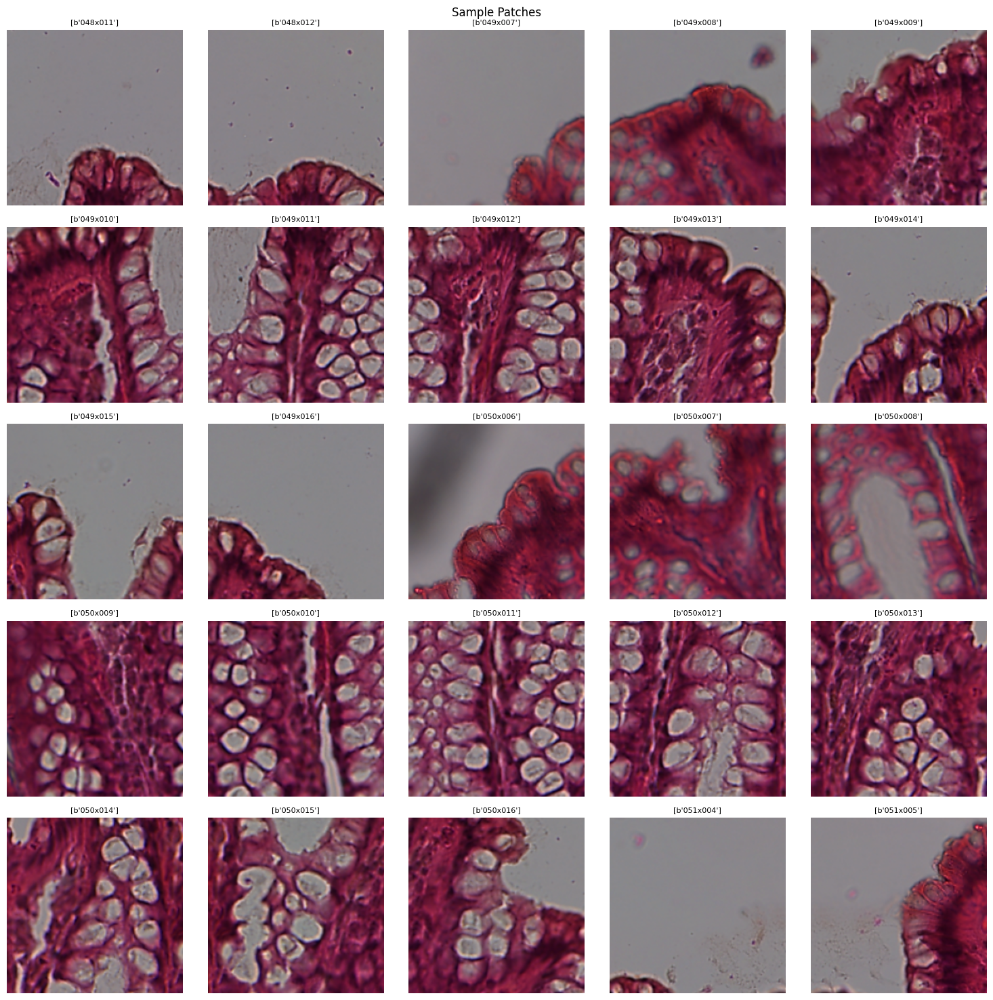

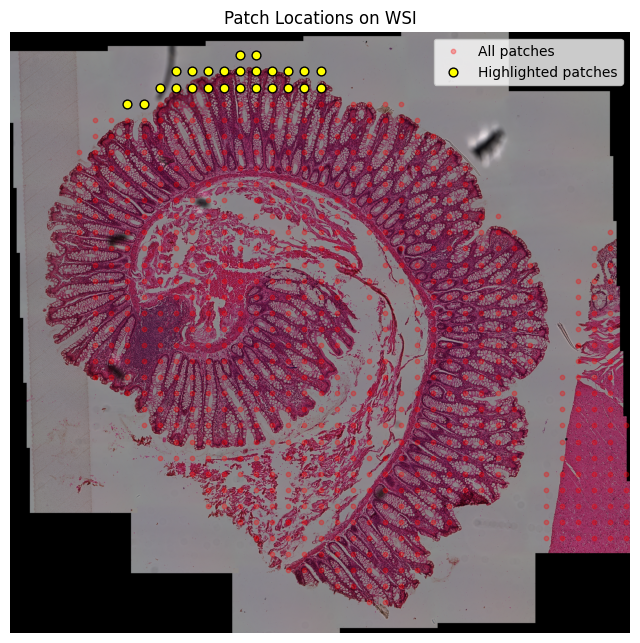

In [8]:
hest_root = "/project/simmons_hts/kxu/hest/data"
h5_file = Path(hest_root) / "patches/XeniumPR1S1ROI1.h5"
wsi_image = Path(hest_root) / "wsis/XeniumPR1S1ROI1.tif"  # downscaled WSI for visualization

visualise_first_n_patches(h5_file, wsi_path=wsi_image, max_patches=25)

In [7]:
def visualise_patch_block(h5_file_path, wsi_path=None, block_size=3, highlight_color="yellow"):
    """
    Visualize a consecutive block of patches (e.g., 5x5) and their locations on the WSI.

    Args:
        h5_file_path (str or Path): path to the patch .h5 file
        wsi_path (str or Path, optional): path to the downscaled WSI image for background
        block_size (int): size of the patch block (block_size x block_size)
        highlight_color (str): color to highlight selected patches on WSI
    """
    h5_file_path = Path(h5_file_path)
    
    with h5py.File(h5_file_path, "r") as f:
        patches = f["img"][:]         # shape: (num_patches, H, W, C)
        coords = f["coords"][:]       # shape: (num_patches, 2) top-left x, y
        barcodes = f["barcode"][:]    # barcodes (optional)

    num_patches = patches.shape[0]

    # normalize coords into grid (unique x/y values sorted)
    xs = np.unique(coords[:,0])
    ys = np.unique(coords[:,1])
    xs.sort()
    ys.sort()

    # make lookup dict: (x,y) -> index in patches
    coord_to_idx = {(x,y): i for i,(x,y) in enumerate(coords)}

    # choose a random valid starting position for a block
    max_x_start = len(xs) - block_size
    max_y_start = len(ys) - block_size
    if max_x_start <= 0 or max_y_start <= 0:
        raise ValueError("Not enough patches to form a block!")

    start_x_idx = np.random.randint(0, max_x_start)
    start_y_idx = np.random.randint(0, max_y_start)

    chosen_indices = []
    for yi in range(start_y_idx, start_y_idx+block_size):
        for xi in range(start_x_idx, start_x_idx+block_size):
            x = xs[xi]
            y = ys[yi]
            if (x,y) in coord_to_idx:
                chosen_indices.append(coord_to_idx[(x,y)])

    chosen_indices = np.array(chosen_indices)
    chosen_patches = patches[chosen_indices]
    chosen_coords = coords[chosen_indices]
    chosen_barcodes = barcodes[chosen_indices]

    print(f"Selected {len(chosen_indices)} patches forming a {block_size}x{block_size} grid")

    # -------------------
    # 1️⃣ Show patch block grid in spatial order
    # -------------------
    plt.figure(figsize=(3*block_size, 3*block_size))
    for j, yi in enumerate(range(start_y_idx, start_y_idx+block_size)):
        for i, xi in enumerate(range(start_x_idx, start_x_idx+block_size)):
            plt.subplot(block_size, block_size, j*block_size + i + 1)
            x = xs[xi]
            y = ys[yi]
            if (x,y) in coord_to_idx:
                idx = coord_to_idx[(x,y)]
                plt.imshow(patches[idx])
                title = barcodes[idx].decode("utf-8") if isinstance(barcodes[idx], bytes) else str(barcodes[idx])
                plt.title(title, fontsize=6)
            plt.axis("off")
    plt.suptitle(f"Random {block_size}x{block_size} Patch Block")
    plt.tight_layout()
    plt.show()

    # -------------------
    # 2️⃣ Show patch block locations on WSI
    # -------------------
    if wsi_path is not None:
        wsi = Image.open(wsi_path)
        wsi = np.array(wsi)

        plt.figure(figsize=(8,8))
        plt.imshow(wsi)

        # plot ALL patches in faint red
        plt.scatter(coords[:,0], coords[:,1], s=10, c="red", alpha=0.2)

        # highlight the block
        plt.scatter(chosen_coords[:,0], chosen_coords[:,1],
                    s=50, c=highlight_color, edgecolor="black")

        plt.title(f"{block_size}x{block_size} Patch Block on WSI")
        plt.axis("off")
        plt.show()
    else:
        print("[INFO] wsi_path not provided, skipping WSI overlay.")


Selected 9 patches forming a 3x3 grid


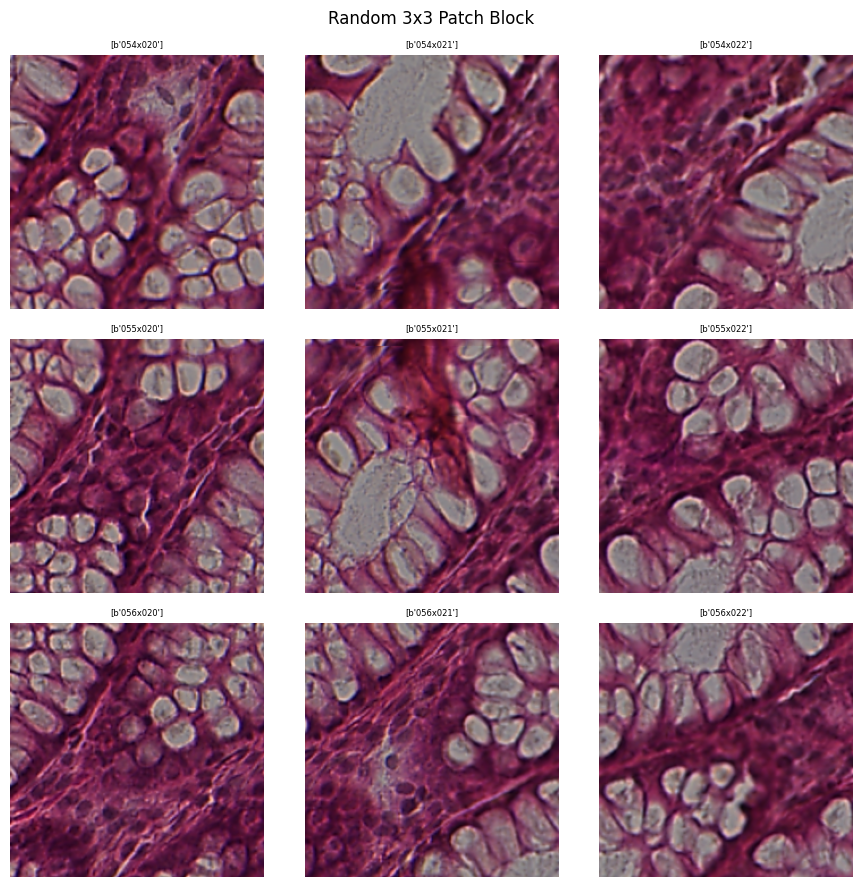

In [8]:
hest_root = "/project/simmons_hts/kxu/hest/data"
h5_file = Path(hest_root) / "patches/XeniumPR1S1ROI1.h5"
wsi_image = Path(hest_root) / "wsis/XeniumPR1S1ROI1.tif"  # downscaled WSI for visualization

visualise_patch_block(h5_file, wsi_path=wsi_image)

# Patching for Broad Samples

[INFO] Auto-detected 7 sample folders: ['DC5', 'UC1_I', 'UC1_NI', 'UC6_I', 'UC6_NI', 'UC7_I', 'UC9_I']
        'pixel_size' is 0.2125
        'wsi' is <width=51136, height=47657, backend=CuImageWSI>
        'shapes': []
[INFO] DC5: tissue_seg present = True


100%|██████████| 5644/5644 [00:34<00:00, 162.93it/s]


found 0 valid patches
[INFO] Patches saved for DC5: /project/simmons_hts/kxu/hest/xenium_data/broad/DC5/patches/DC5.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/broad/DC5/patches_vis/DC5_patch_vis.png
        'pixel_size' is 0.2125
        'wsi' is <width=51147, height=47659, backend=CuImageWSI>
        'shapes': []
[INFO] UC1_I: tissue_seg present = True


100%|██████████| 6549/6549 [00:39<00:00, 166.64it/s]


found 0 valid patches
[INFO] Patches saved for UC1_I: /project/simmons_hts/kxu/hest/xenium_data/broad/UC1_I/patches/UC1_I.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/broad/UC1_I/patches_vis/UC1_I_patch_vis.png
        'pixel_size' is 0.2125
        'wsi' is <width=53998, height=51060, backend=CuImageWSI>
        'shapes': []
[INFO] UC1_NI: tissue_seg present = True


100%|██████████| 4518/4518 [00:30<00:00, 149.40it/s]


found 0 valid patches
[INFO] Patches saved for UC1_NI: /project/simmons_hts/kxu/hest/xenium_data/broad/UC1_NI/patches/UC1_NI.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/broad/UC1_NI/patches_vis/UC1_NI_patch_vis.png
        'pixel_size' is 0.2125
        'wsi' is <width=54010, height=57868, backend=CuImageWSI>
        'shapes': []
[INFO] UC6_I: tissue_seg present = True


100%|██████████| 6966/6966 [00:38<00:00, 180.01it/s]


found 0 valid patches
[INFO] Patches saved for UC6_I: /project/simmons_hts/kxu/hest/xenium_data/broad/UC6_I/patches/UC6_I.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/broad/UC6_I/patches_vis/UC6_I_patch_vis.png
        'pixel_size' is 0.2125
        'wsi' is <width=53985, height=47668, backend=CuImageWSI>
        'shapes': []
[INFO] UC6_NI: tissue_seg present = True


100%|██████████| 4812/4812 [00:32<00:00, 146.93it/s]


found 0 valid patches
[INFO] Patches saved for UC6_NI: /project/simmons_hts/kxu/hest/xenium_data/broad/UC6_NI/patches/UC6_NI.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/broad/UC6_NI/patches_vis/UC6_NI_patch_vis.png
        'pixel_size' is 0.2125
        'wsi' is <width=54005, height=44279, backend=CuImageWSI>
        'shapes': []
[INFO] UC7_I: tissue_seg present = True


100%|██████████| 3607/3607 [00:28<00:00, 126.75it/s]


found 0 valid patches
[INFO] Patches saved for UC7_I: /project/simmons_hts/kxu/hest/xenium_data/broad/UC7_I/patches/UC7_I.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/broad/UC7_I/patches_vis/UC7_I_patch_vis.png


/project/simmons_hts/kxu/hest/xenium_data/broad/UC9_I/aligned_fullres_HE.tif: Failed to allocate memory for to read TIFF directory (0 elements of 12 bytes each).
TIFFReadDirectory: Failed to read directory at offset 4294948320.


        'pixel_size' is 0.2125
        'wsi' is <width=53986, height=57853, backend=CuImageWSI>
        'shapes': []
[INFO] UC9_I: tissue_seg present = True


100%|██████████| 7335/7335 [00:40<00:00, 179.22it/s]


found 0 valid patches
[INFO] Patches saved for UC9_I: /project/simmons_hts/kxu/hest/xenium_data/broad/UC9_I/patches/UC9_I.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/broad/UC9_I/patches_vis/UC9_I_patch_vis.png


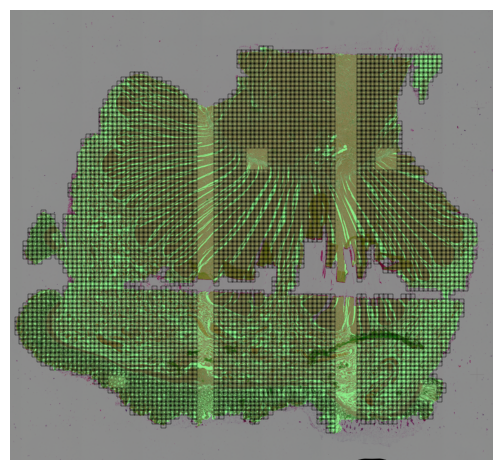

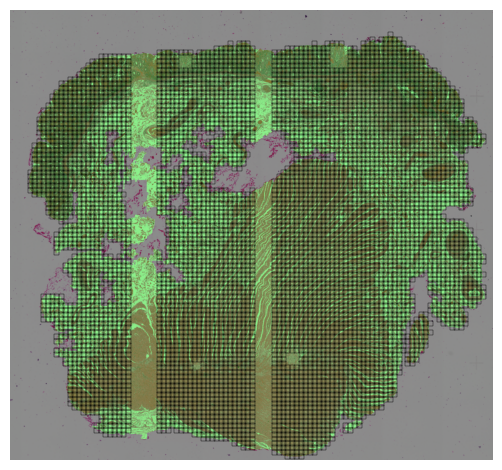

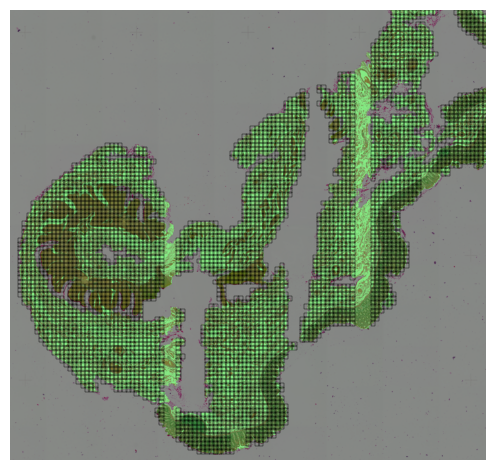

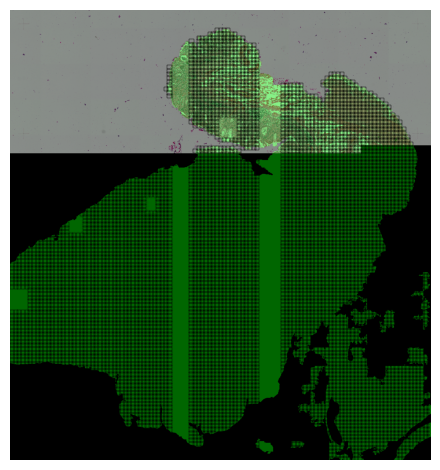

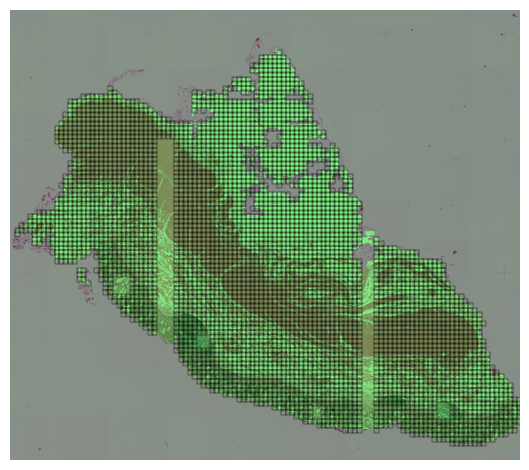

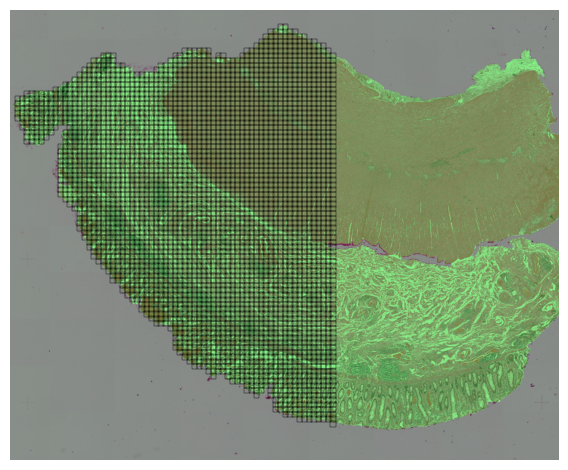

In [20]:
patch_hest_samples()

In [6]:
show_images("/project/simmons_hts/kxu/hest/xenium_data/broad", subfolders=("patches_vis",))
# UC6_I HE image only shows top one third but that's fine

In [ ]:
# Example usage:
df_counts = count_patches("/project/simmons_hts/kxu/hest/xenium_data/broad/", save_csv="patch_counts.csv")

## visualise patches in a memory light way (dont use tif but use downscaled jpeg)

In [19]:
import numpy as np
import h5py
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

def visualise_patch_block(
    h5_file_path,
    jpeg_path,                       # path to downscaled_fullres.jpeg
    fullres_size=None,               # (H_full, W_full); if None we infer from coords
    block_size=3,
    highlight_color="yellow",
    max_display_side_px=2000,        # cap JPEG display size for plotting
):
    """
    Visualize a consecutive block of patches and their locations using *downscaled_fullres.jpeg*,
    with patch coordinates stored in ORIGINAL WSI pixels (no giant TIFF reads).

    Args:
        h5_file_path (str|Path): patch .h5 file (expects datasets: img, coords/xy, optional barcode)
        jpeg_path (str|Path): path to downscaled_fullres.jpeg (background)
        fullres_size (tuple|None): (H_full, W_full) of the original WSI. If None, infer from coords.
        block_size (int): block side length (block_size x block_size)
        highlight_color (str): rectangle color for selected patches
        max_display_side_px (int): cap long edge of displayed JPEG to keep figure reasonable
    """
    h5_file_path = Path(h5_file_path)
    jpeg_path = Path(jpeg_path)

    # ---------- Load minimal H5 metadata (NO full arrays) ----------
    with h5py.File(h5_file_path, "r") as f:
        # coords: accept several common keys
        if "coords" in f:
            coords = f["coords"][...]            # (N, 2) top-left (x, y) at FULL-RES pixels
        elif "xy" in f:
            coords = f["xy"][...]
        else:
            raise KeyError("No 'coords' or 'xy' dataset in the H5 file.")

        # patch size from img dataset shape (N, H, W, [C])
        ish = f["img"].shape
        patch_h, patch_w = int(ish[1]), int(ish[2])

        has_barcodes = "barcode" in f
        barcodes_ds = f["barcode"] if has_barcodes else None

        # grid indexing from coords
        xs = np.unique(coords[:, 0]); xs.sort()
        ys = np.unique(coords[:, 1]); ys.sort()
        coord_to_idx = {(int(x), int(y)): i for i, (x, y) in enumerate(coords)}

        max_x_start = len(xs) - block_size
        max_y_start = len(ys) - block_size
        if max_x_start <= 0 or max_y_start <= 0:
            raise ValueError("Not enough patches to form a block!")

        start_x_idx = np.random.randint(0, max_x_start)
        start_y_idx = np.random.randint(0, max_y_start)

        chosen_indices, chosen_xy = [], []
        for yi in range(start_y_idx, start_y_idx + block_size):
            for xi in range(start_x_idx, start_x_idx + block_size):
                x = int(xs[xi]); y = int(ys[yi])
                if (x, y) in coord_to_idx:
                    idx = coord_to_idx[(x, y)]
                    chosen_indices.append(idx)
                    chosen_xy.append((x, y))
        chosen_indices = np.array(chosen_indices, dtype=int)
        chosen_xy = np.array(chosen_xy, dtype=int)

        print(f"Selected {len(chosen_indices)} patches forming a {block_size}x{block_size} grid")

        # ---------- (1) Patch block grid (stream from HDF5) ----------
        plt.figure(figsize=(3 * block_size, 3 * block_size))
        k = 0
        for j in range(block_size):
            for i in range(block_size):
                ax = plt.subplot(block_size, block_size, j * block_size + i + 1)
                if k < len(chosen_indices):
                    idx = int(chosen_indices[k])
                    patch = f["img"][idx]  # read only this patch
                    ax.imshow(patch)
                    if has_barcodes:
                        b = barcodes_ds[idx]
                        title = b.decode("utf-8") if isinstance(b, (bytes, np.bytes_)) else str(b)
                        ax.set_title(title, fontsize=6)
                    k += 1
                ax.axis("off")
        plt.suptitle(f"Random {block_size}x{block_size} Patch Block")
        plt.tight_layout()
        plt.show()

    # ---------- (2) Overlay on downscaled_fullres.jpeg (no TIFF) ----------
    jpeg_img = Image.open(jpeg_path).convert("RGB")
    Wj, Hj = jpeg_img.size  # PIL: (width, height)

    # Determine full-res WSI (H_full, W_full) → used ONLY for scaling coords to JPEG space
    if fullres_size is not None:
        Hf, Wf = map(int, fullres_size)
    else:
        # Infer from max coords + patch size (works well if coords cover slide)
        xmax = int(coords[:, 0].max() + patch_w)
        ymax = int(coords[:, 1].max() + patch_h)
        Wf, Hf = xmax, ymax
        # (Optional) print a hint so you can provide exact dims next time if needed
        print("[INFO] fullres_size not provided; inferred from coords as "
              f"(H_full={Hf}, W_full={Wf}). Pass fullres_size=(H,W) for exact scaling.")

    # Scale factors: FULL-RES → JPEG
    sx = Wj / float(Wf)
    sy = Hj / float(Hf)

    # Map selected coords + patch size to JPEG space
    chosen_xy_disp = chosen_xy.astype(np.float64)
    chosen_xy_disp[:, 0] *= sx
    chosen_xy_disp[:, 1] *= sy
    pw_disp = patch_w * sx
    ph_disp = patch_h * sy

    # Downscale the displayed JPEG if it's huge so the figure always renders fully
    long_edge = max(Wj, Hj)
    disp_scale = 1.0 if long_edge <= max_display_side_px else (max_display_side_px / float(long_edge))
    if disp_scale < 1.0:
        new_w = int(Wj * disp_scale)
        new_h = int(Hj * disp_scale)
        jpeg_disp = jpeg_img.resize((new_w, new_h), Image.LANCZOS)
    else:
        jpeg_disp = jpeg_img
        new_w, new_h = Wj, Hj

    # Apply display scale to coords/size
    chosen_xy_disp *= disp_scale
    pw_d = pw_disp * disp_scale
    ph_d = ph_disp * disp_scale

    # Draw only the chosen block on the JPEG background (fast)
    dpi = 100
    fig_w_in, fig_h_in = new_w / dpi, new_h / dpi
    fig, ax = plt.subplots(figsize=(fig_w_in, fig_h_in), dpi=dpi)
    ax.imshow(jpeg_disp)
    ax.set_axis_off()

    for (x, y) in chosen_xy_disp:
        ax.add_patch(Rectangle((x, y), pw_d, ph_d, fill=False,
                               linewidth=1.0, edgecolor=highlight_color))
        ax.plot(x + pw_d / 2, y + ph_d / 2, "o", ms=3, mec="black", mfc=highlight_color)

    plt.tight_layout(pad=0)
    plt.show()


In [21]:
import numpy as np
import h5py
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

def visualise_patch_block(
    h5_file_path,
    jpeg_path,                       # path to downscaled_fullres.jpeg
    fullres_size=None,               # (H_full, W_full); if None we infer from coords
    block_size=3,
    highlight_color="yellow",
    max_display_side_px=2000,        # cap JPEG display size for plotting
    selection_method="auto",         # 'auto' (try strict then fallback), 'strict', or 'nearest'
):
    """
    Visualize a consecutive block of patches and their locations using *downscaled_fullres.jpeg*,
    with patch coordinates stored in ORIGINAL WSI pixels (no giant TIFF reads).

    Args:
        h5_file_path (str|Path): patch .h5 file (expects datasets: img, coords/xy, optional barcode)
        jpeg_path (str|Path): path to downscaled_fullres.jpeg (background)
        fullres_size (tuple|None): (H_full, W_full) of the original WSI. If None, infer from coords.
        block_size (int): block side length (block_size x block_size)
        highlight_color (str): rectangle color for selected patches
        max_display_side_px (int): cap long edge of displayed JPEG to keep figure reasonable
        selection_method (str): 'auto' (default) tries strict-grid then falls back to nearest-neighbour,
                                'strict' forces the original exact-grid behaviour (may raise if no block),
                                'nearest' forces nearest-neighbour selection.
    """
    h5_file_path = Path(h5_file_path)
    jpeg_path = Path(jpeg_path)

    # ---------- Load minimal H5 metadata (NO full arrays) ----------
    with h5py.File(h5_file_path, "r") as f:
        # coords: accept several common keys
        if "coords" in f:
            coords = f["coords"][...]            # (N, 2) top-left (x, y) at FULL-RES pixels
        elif "xy" in f:
            coords = f["xy"][...]
        else:
            raise KeyError("No 'coords' or 'xy' dataset in the H5 file.")

        # patch size from img dataset shape (N, H, W, [C])
        ish = f["img"].shape
        patch_h, patch_w = int(ish[1]), int(ish[2])

        has_barcodes = "barcode" in f
        barcodes_ds = f["barcode"] if has_barcodes else None

        # Build helpful lookup structures
        xs = np.unique(coords[:, 0]); xs.sort()
        ys = np.unique(coords[:, 1]); ys.sort()
        coord_to_idx = {(int(x), int(y)): i for i, (x, y) in enumerate(coords)}

        desired_n = block_size * block_size
        chosen_indices = np.array([], dtype=int)
        chosen_xy = np.zeros((0, 2), dtype=int)
        used_fallback = False

        def strict_grid_selection():
            """Attempt strict grid selection using unique xs/ys indices."""
            max_x_start = len(xs) - block_size
            max_y_start = len(ys) - block_size
            sel_idx = []
            sel_xy = []
            if max_x_start > 0 and max_y_start > 0:
                start_x_idx = np.random.randint(0, max_x_start)
                start_y_idx = np.random.randint(0, max_y_start)
                for yi in range(start_y_idx, start_y_idx + block_size):
                    for xi in range(start_x_idx, start_x_idx + block_size):
                        x = int(xs[xi]); y = int(ys[yi])
                        if (x, y) in coord_to_idx:
                            idx = coord_to_idx[(x, y)]
                            sel_idx.append(idx)
                            sel_xy.append((x, y))
            return np.array(sel_idx, dtype=int), np.array(sel_xy, dtype=int)

        def nearest_neighbour_block():
            """Select nearest `desired_n` neighbours around a random seed and order them row->col."""
            if coords.shape[0] < desired_n:
                # Not enough patches in total
                nn_idx = np.argsort(((coords - coords.mean(axis=0))**2).sum(axis=1))
                nn_idx = nn_idx[:coords.shape[0]]
            else:
                seed_idx = np.random.randint(0, coords.shape[0])
                seed_xy = coords[seed_idx].astype(np.float64)
                diffs = coords.astype(np.float64) - seed_xy[None, :]
                d2 = (diffs ** 2).sum(axis=1)
                nn_idx = np.argsort(d2)[:desired_n]

            nn_coords = coords[nn_idx].astype(int)

            # Try to create a row ordering. Compute approximate row height from y-values
            y_vals_unique = np.unique(nn_coords[:, 1])
            if len(y_vals_unique) > 1:
                sorted_y = np.sort(y_vals_unique)
                dy = np.diff(sorted_y)
                # if all dy equal zero (unlikely) fallback to patch_h
                median_dy = int(np.median(dy)) if len(dy) >= 1 else patch_h
                row_height = max(1, median_dy)
            else:
                row_height = patch_h

            row_ids = ((nn_coords[:, 1] - nn_coords[:, 1].min()) // row_height).astype(int)
            order = np.lexsort((nn_coords[:, 0], row_ids))  # sort by row (y), then x
            ordered_idx = nn_idx[order]
            return np.array(ordered_idx, dtype=int), coords[ordered_idx].astype(int)

        # Selection strategy
        if selection_method == "strict":
            chosen_indices, chosen_xy = strict_grid_selection()
            used_fallback = False
        elif selection_method == "nearest":
            chosen_indices, chosen_xy = nearest_neighbour_block()
            used_fallback = True
        else:  # auto: try strict, then fallback
            chosen_indices, chosen_xy = strict_grid_selection()
            if chosen_indices.size < desired_n:
                chosen_indices, chosen_xy = nearest_neighbour_block()
                used_fallback = True

        # If even after fallback we have fewer than desired, clamp to available
        if chosen_indices.size == 0:
            # nothing selected; raise a clearer error
            raise ValueError(f"Could not select any patches (found {coords.shape[0]} total). "
                             "Check that coords are present and non-empty.")
        if chosen_indices.size < desired_n:
            print(f"[WARN] only {chosen_indices.size}/{desired_n} patches available for display; "
                  "display will be partially empty.")
        print(f"Selected {len(chosen_indices)} patches (fallback used: {used_fallback})")

        # ---------- (1) Patch block grid (stream from HDF5) ----------
        plt.figure(figsize=(3 * block_size, 3 * block_size))
        k = 0
        for j in range(block_size):
            for i in range(block_size):
                ax = plt.subplot(block_size, block_size, j * block_size + i + 1)
                if k < len(chosen_indices):
                    idx = int(chosen_indices[k])
                    patch = f["img"][idx]  # read only this patch
                    ax.imshow(patch)
                    if has_barcodes:
                        b = barcodes_ds[idx]
                        title = b.decode("utf-8") if isinstance(b, (bytes, np.bytes_)) else str(b)
                        ax.set_title(title, fontsize=6)
                else:
                    # empty cell
                    ax.axis("off")
                k += 1
        plt.suptitle(f"Patch Block (method='{selection_method}', fallback={used_fallback})")
        plt.tight_layout()
        plt.show()

    # ---------- (2) Overlay on downscaled_fullres.jpeg (no TIFF) ----------
    jpeg_img = Image.open(jpeg_path).convert("RGB")
    Wj, Hj = jpeg_img.size  # PIL: (width, height)

    # Determine full-res WSI (H_full, W_full) → used ONLY for scaling coords to JPEG space
    if fullres_size is not None:
        Hf, Wf = map(int, fullres_size)
    else:
        # Infer from max coords + patch size (works well if coords cover slide)
        xmax = int(coords[:, 0].max() + patch_w)
        ymax = int(coords[:, 1].max() + patch_h)
        Wf, Hf = xmax, ymax
        print("[INFO] fullres_size not provided; inferred from coords as "
              f"(H_full={Hf}, W_full={Wf}). Pass fullres_size=(H,W) for exact scaling.")

    # Scale factors: FULL-RES → JPEG
    sx = Wj / float(Wf) if Wf > 0 else 1.0
    sy = Hj / float(Hf) if Hf > 0 else 1.0

    # Map selected coords + patch size to JPEG space
    # chosen_xy may contain fewer than desired_n; that's OK
    chosen_xy_disp = chosen_xy.astype(np.float64).copy()
    chosen_xy_disp[:, 0] *= sx
    chosen_xy_disp[:, 1] *= sy
    pw_disp = patch_w * sx
    ph_disp = patch_h * sy

    # Downscale the displayed JPEG if it's huge so the figure always renders fully
    long_edge = max(Wj, Hj)
    disp_scale = 1.0 if long_edge <= max_display_side_px else (max_display_side_px / float(long_edge))
    if disp_scale < 1.0:
        new_w = int(Wj * disp_scale)
        new_h = int(Hj * disp_scale)
        jpeg_disp = jpeg_img.resize((new_w, new_h), Image.LANCZOS)
    else:
        jpeg_disp = jpeg_img
        new_w, new_h = Wj, Hj

    # Apply display scale to coords/size
    chosen_xy_disp *= disp_scale
    pw_d = pw_disp * disp_scale
    ph_d = ph_disp * disp_scale

    # Draw only the chosen block on the JPEG background (fast)
    dpi = 100
    fig_w_in, fig_h_in = new_w / dpi, new_h / dpi
    fig, ax = plt.subplots(figsize=(fig_w_in, fig_h_in), dpi=dpi)
    ax.imshow(jpeg_disp)
    ax.set_axis_off()

    for (x, y) in chosen_xy_disp:
        ax.add_patch(Rectangle((x, y), pw_d, ph_d, fill=False,
                               linewidth=1.0, edgecolor=highlight_color))
        ax.plot(x + pw_d / 2, y + ph_d / 2, "o", ms=3, mec="black", mfc=highlight_color)

    plt.tight_layout(pad=0)
    plt.show()


Selected 25 patches (fallback used: True)


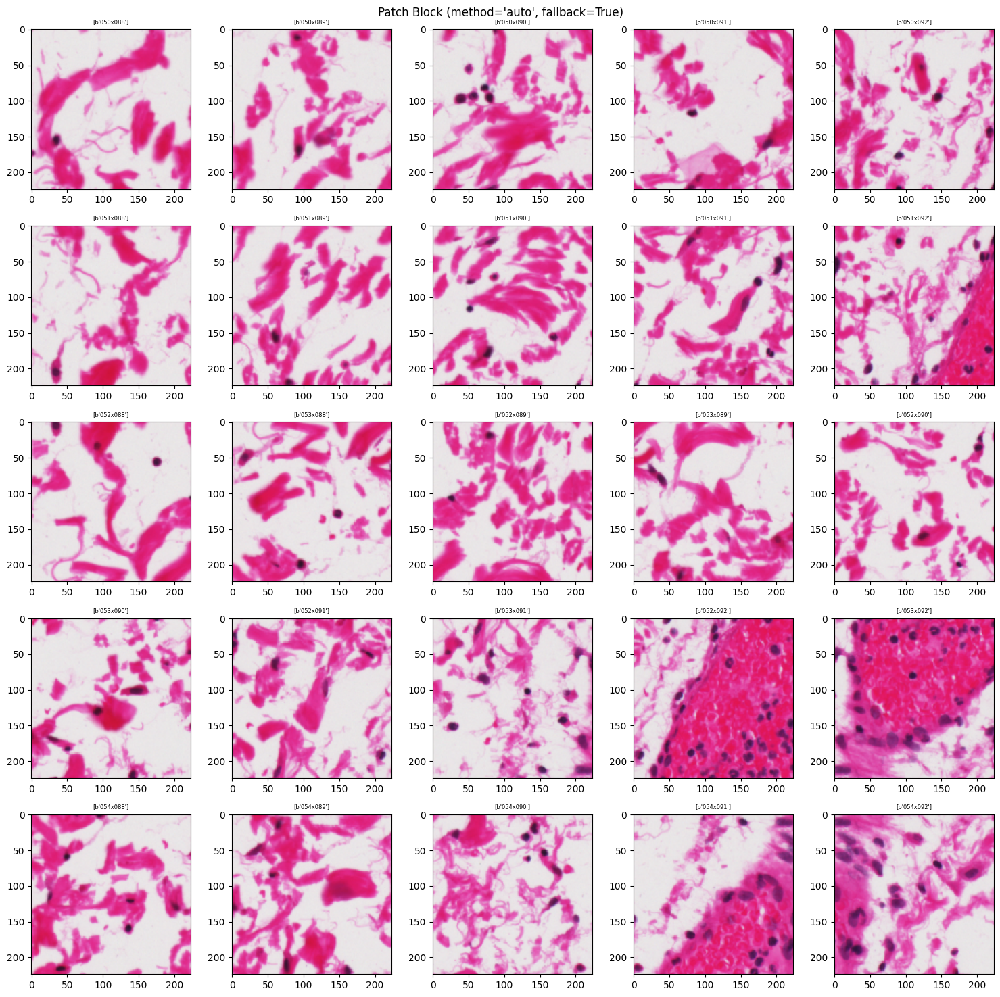

[INFO] fullres_size not provided; inferred from coords as (H_full=47262, W_full=50086). Pass fullres_size=(H,W) for exact scaling.


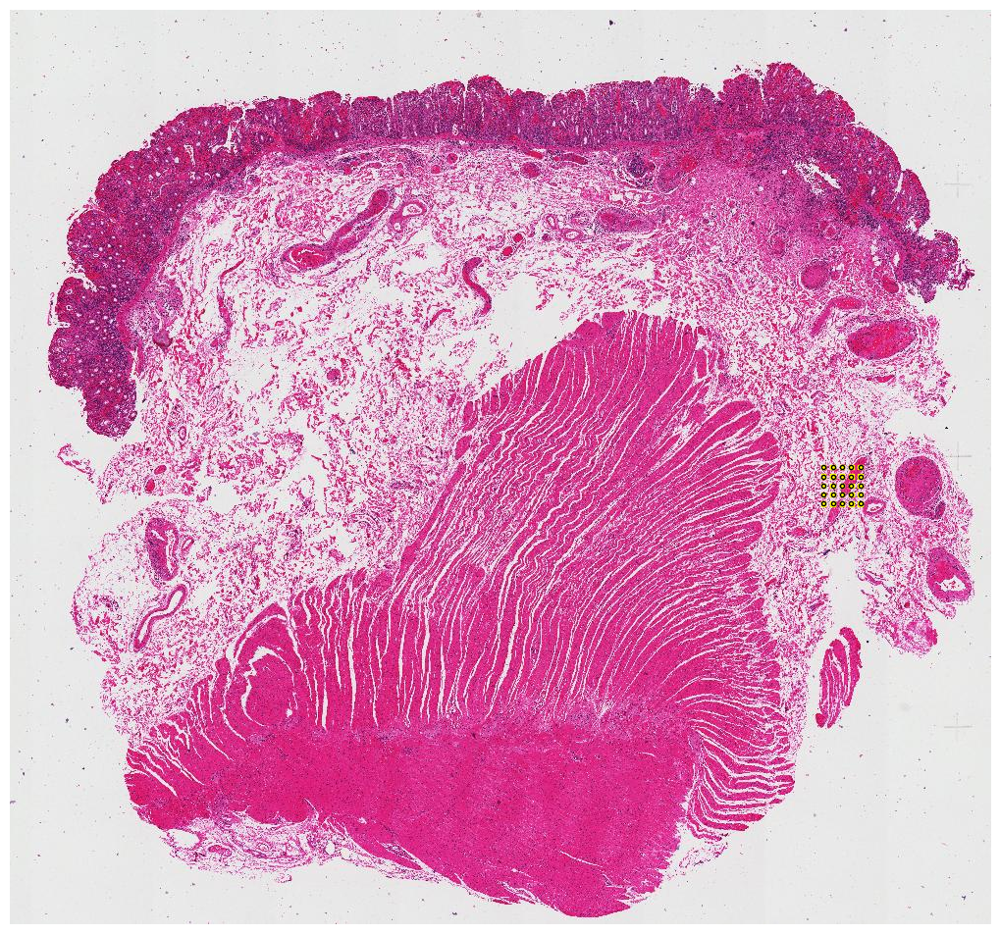

In [22]:
# paths
hest_root = Path("/project/simmons_hts/kxu/hest/xenium_data/broad/UC1_I")
h5_file   = hest_root / "patches" / "UC1_I.h5"
jpeg_path = hest_root / "downscaled_fullres.jpeg"   # use this as the background (fast)

# simplest: let the function infer full-res dims from coords
visualise_patch_block(
    h5_file_path=h5_file,
    jpeg_path=jpeg_path,
    block_size=5,                 # e.g., 5x5 block
    highlight_color="yellow",
    max_display_side_px=2000
)

# Patching for XeniumPR1_segger Samples

[INFO] Auto-detected 8 sample folders: ['ROI1', 'ROI2', 'ROI3', 'ROI4', 'ROI5', 'ROI6', 'ROI7', 'ROI8']
        'pixel_size' is 0.4353514884015406
        'wsi' is <width=8851, height=8585, backend=CuImageWSI>
        'shapes': []
[INFO] ROI1: tissue_seg present = True


100%|██████████| 684/684 [00:04<00:00, 162.59it/s]


found 0 valid patches
[INFO] Patches saved for ROI1: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI1/patches/ROI1.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI1/patches_vis/ROI1_patch_vis.png
        'pixel_size' is 0.43561023341205224
        'wsi' is <width=7408, height=10434, backend=CuImageWSI>
        'shapes': []
[INFO] ROI2: tissue_seg present = True


100%|██████████| 482/482 [00:02<00:00, 162.11it/s]


found 0 valid patches
[INFO] Patches saved for ROI2: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI2/patches/ROI2.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI2/patches_vis/ROI2_patch_vis.png
        'pixel_size' is 0.4346822863887948
        'wsi' is <width=12994, height=8725, backend=CuImageWSI>
        'shapes': []
[INFO] ROI3: tissue_seg present = True


100%|██████████| 1168/1168 [00:07<00:00, 166.82it/s]


found 0 valid patches
[INFO] Patches saved for ROI3: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI3/patches/ROI3.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI3/patches_vis/ROI3_patch_vis.png
        'pixel_size' is 0.43509460497596525
        'wsi' is <width=14343, height=8724, backend=CuImageWSI>
        'shapes': []
[INFO] ROI4: tissue_seg present = True


100%|██████████| 1253/1253 [00:07<00:00, 176.85it/s]


found 0 valid patches
[INFO] Patches saved for ROI4: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI4/patches/ROI4.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI4/patches_vis/ROI4_patch_vis.png
        'pixel_size' is 0.4342285450650283
        'wsi' is <width=29752, height=7302, backend=CuImageWSI>
        'shapes': []
[INFO] ROI5: tissue_seg present = True


100%|██████████| 893/893 [00:05<00:00, 154.88it/s]


found 0 valid patches
[INFO] Patches saved for ROI5: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI5/patches/ROI5.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI5/patches_vis/ROI5_patch_vis.png
        'pixel_size' is 0.434453340495722
        'wsi' is <width=25467, height=11081, backend=CuImageWSI>
        'shapes': []
[INFO] ROI6: tissue_seg present = True


100%|██████████| 2665/2665 [00:15<00:00, 171.81it/s]


found 0 valid patches
[INFO] Patches saved for ROI6: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI6/patches/ROI6.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI6/patches_vis/ROI6_patch_vis.png
        'pixel_size' is 0.4338127352315242
        'wsi' is <width=22924, height=12938, backend=CuImageWSI>
        'shapes': []
[INFO] ROI7: tissue_seg present = True


100%|██████████| 2419/2419 [00:14<00:00, 171.27it/s]


found 0 valid patches
[INFO] Patches saved for ROI7: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI7/patches/ROI7.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI7/patches_vis/ROI7_patch_vis.png
        'pixel_size' is 0.4370543529121492
        'wsi' is <width=22816, height=13369, backend=CuImageWSI>
        'shapes': []
[INFO] ROI8: tissue_seg present = True


100%|██████████| 3291/3291 [00:17<00:00, 183.00it/s]


found 0 valid patches
[INFO] Patches saved for ROI8: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI8/patches/ROI8.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/ROI8/patches_vis/ROI8_patch_vis.png


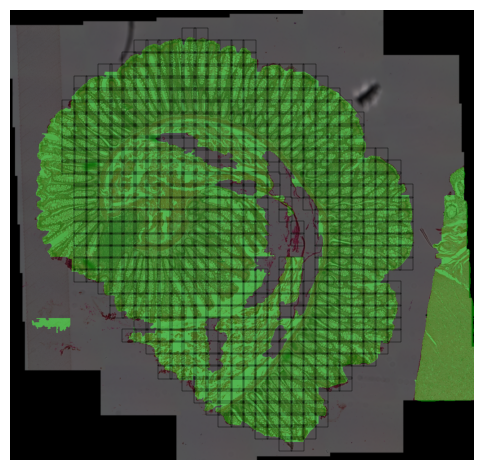

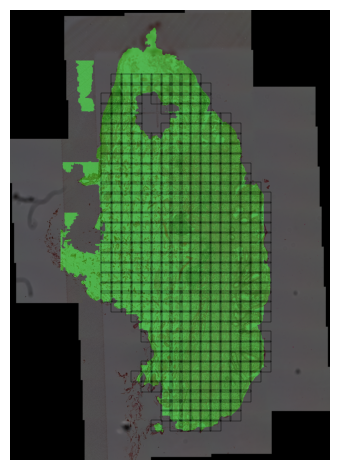

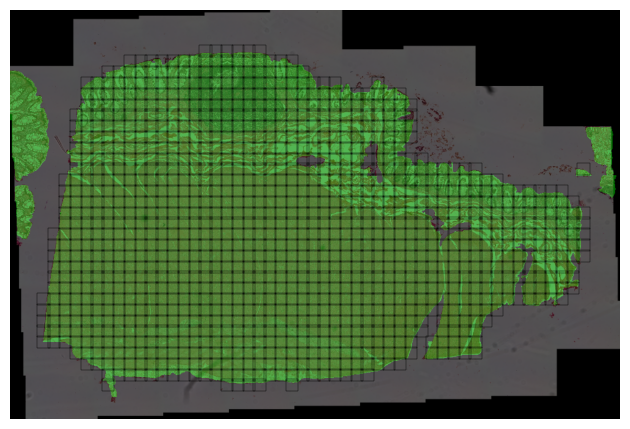

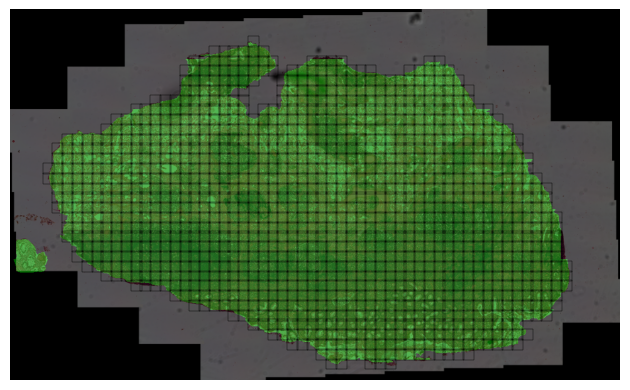

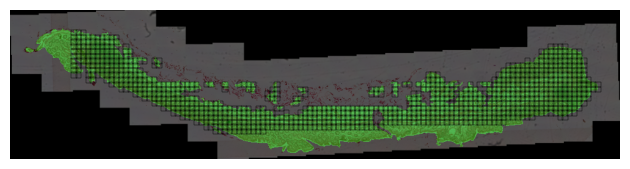

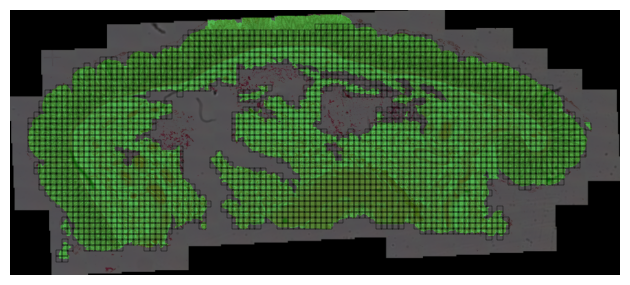

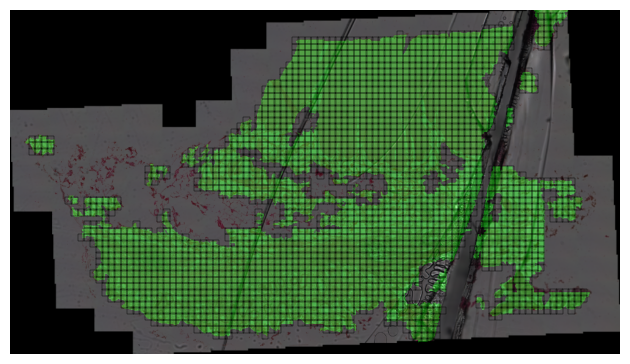

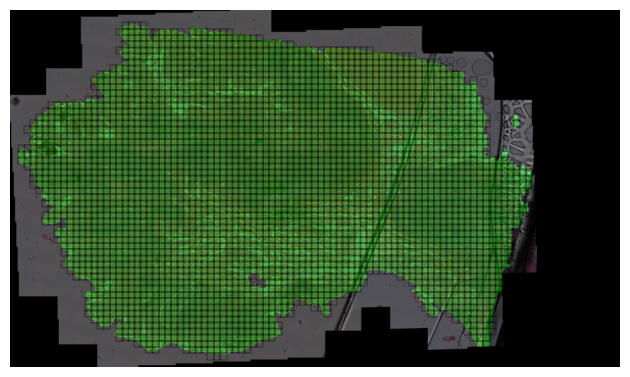

In [7]:
patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

[INFO] Auto-detected 8 sample folders: ['ROI1', 'ROI2', 'ROI3', 'ROI4', 'ROI5', 'ROI6', 'ROI7', 'tissue_seg']
        'pixel_size' is 0.43483325563202857
        'wsi' is <width=17305, height=16539, backend=CuImageWSI>
        'shapes': []
[INFO] ROI1: tissue_seg present = True


100%|██████████| 2799/2799 [00:16<00:00, 172.83it/s]


found 0 valid patches
[INFO] Patches saved for ROI1: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI1/patches/ROI1.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI1/patches_vis/ROI1_patch_vis.png
        'pixel_size' is 0.4344276223626176
        'wsi' is <width=22676, height=11873, backend=CuImageWSI>
        'shapes': []
[INFO] ROI2: tissue_seg present = True


100%|██████████| 2383/2383 [00:13<00:00, 174.99it/s]


found 0 valid patches
[INFO] Patches saved for ROI2: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI2/patches/ROI2.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI2/patches_vis/ROI2_patch_vis.png
        'pixel_size' is 0.43424436873240163
        'wsi' is <width=15550, height=12731, backend=CuImageWSI>
        'shapes': []
[INFO] ROI3: tissue_seg present = True


100%|██████████| 1514/1514 [00:08<00:00, 173.31it/s]


found 0 valid patches
[INFO] Patches saved for ROI3: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI3/patches/ROI3.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI3/patches_vis/ROI3_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43512933641298734
        'wsi' is <width=19736, height=16011, backend=CuImageWSI>
        'shapes': []
[INFO] ROI4: tissue_seg present = True


100%|██████████| 2674/2674 [00:15<00:00, 167.70it/s]


found 0 valid patches
[INFO] Patches saved for ROI4: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI4/patches/ROI4.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI4/patches_vis/ROI4_patch_vis.png
        'pixel_size' is 0.4346128823579932
        'wsi' is <width=10488, height=12013, backend=CuImageWSI>
        'shapes': []
[INFO] ROI5: tissue_seg present = True


100%|██████████| 892/892 [00:05<00:00, 168.38it/s]


found 0 valid patches
[INFO] Patches saved for ROI5: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI5/patches/ROI5.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI5/patches_vis/ROI5_patch_vis.png
        'pixel_size' is 0.4357339146174697
        'wsi' is <width=11505, height=16363, backend=CuImageWSI>
        'shapes': []
[INFO] ROI6: tissue_seg present = True


100%|██████████| 1631/1631 [00:11<00:00, 144.92it/s]


found 0 valid patches
[INFO] Patches saved for ROI6: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI6/patches/ROI6.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI6/patches_vis/ROI6_patch_vis.png
        'pixel_size' is 0.43486571487000075
        'wsi' is <width=17044, height=10800, backend=CuImageWSI>
        'shapes': []
[INFO] ROI7: tissue_seg present = True


100%|██████████| 1868/1868 [00:10<00:00, 179.75it/s]


found 0 valid patches
[INFO] Patches saved for ROI7: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI7/patches/ROI7.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/ROI7/patches_vis/ROI7_patch_vis.png
[ERROR] Missing required file(s) for tissue_seg: Missing /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/tissue_seg/aligned_adata.h5ad


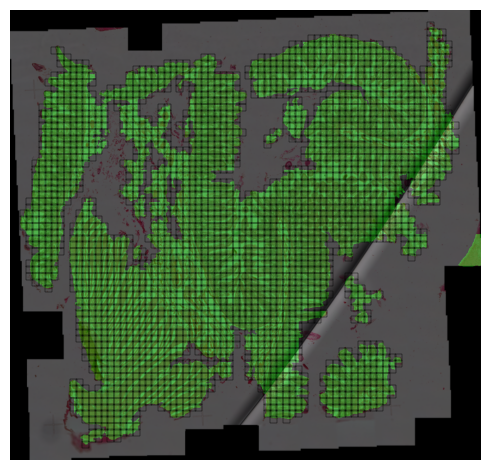

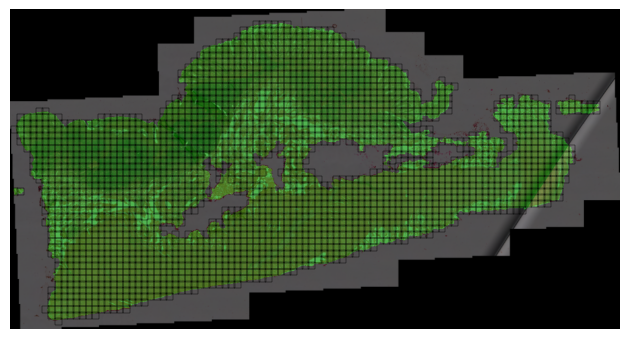

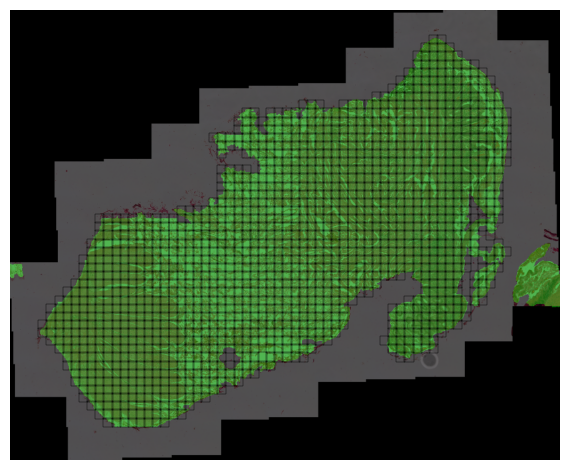

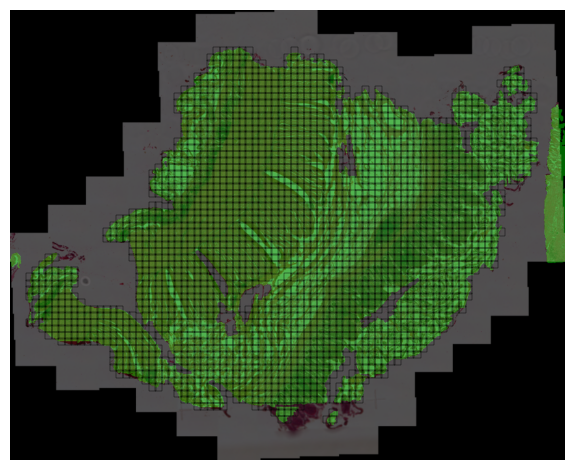

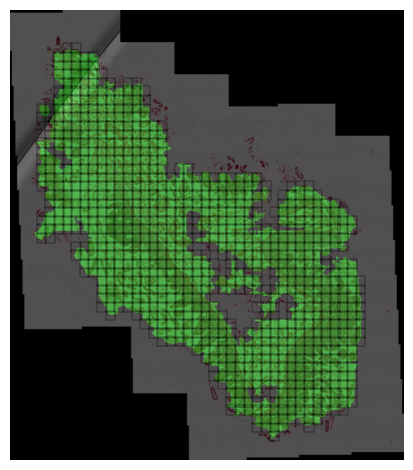

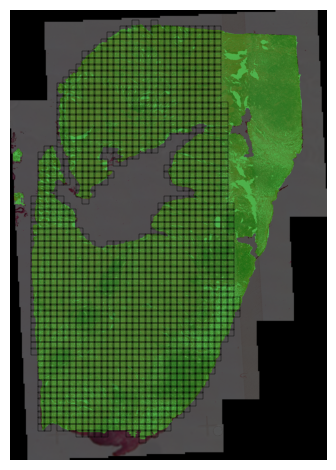

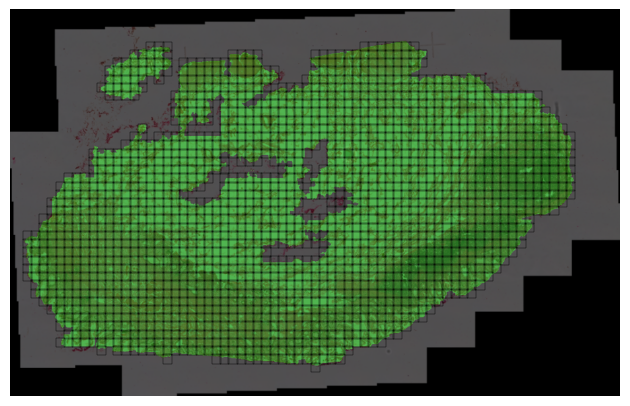

In [8]:
patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

In [6]:
show_images("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2", subfolders=("patches_vis",))

In [7]:
show_images("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1", subfolders=("patches_vis",))

In [8]:
df_counts = count_patches("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1", save_csv="patch_counts.csv")

  sample_id  num_patches
0      ROI1          684
1      ROI2          482
2      ROI3         1168
3      ROI4         1253
4      ROI5          893
5      ROI6         2665
6      ROI7         2419
7      ROI8         3291

Total patches across all samples: 12855
[INFO] Saved counts to /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide1/patch_counts.csv


In [10]:
df_counts = count_patches("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2", save_csv="patch_counts.csv")

  sample_id  num_patches
0      ROI1         2799
1      ROI2         2383
2      ROI3         1514
3      ROI4         2674
4      ROI5          892
5      ROI6         1631
6      ROI7         1868

Total patches across all samples: 13761
[INFO] Saved counts to /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_segger/slide2/patch_counts.csv


# XeniumPR1_50um

### patching at 0.5 um/px (20x mag, patch size = 112 um, spot size = 50 um)

[INFO] Auto-detected 8 sample folders: ['ROI1', 'ROI2', 'ROI3', 'ROI4', 'ROI5', 'ROI6', 'ROI7', 'ROI8']


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4353514884015406
        'wsi' is <width=8851, height=8585, backend=CuImageWSI>
        'shapes': []
[INFO] ROI1: tissue_seg present = True


100%|██████████| 2727/2727 [00:15<00:00, 177.76it/s]


found 0 valid patches
[INFO] Patches saved for ROI1: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI1/patches/ROI1.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI1/patches_vis/ROI1_patch_vis.png
        'pixel_size' is 0.43561023341205224
        'wsi' is <width=7408, height=10434, backend=CuImageWSI>
        'shapes': []


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


[INFO] ROI2: tissue_seg present = True


100%|██████████| 1886/1886 [00:10<00:00, 183.42it/s]


found 0 valid patches
[INFO] Patches saved for ROI2: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI2/patches/ROI2.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI2/patches_vis/ROI2_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4346822863887948
        'wsi' is <width=12994, height=8725, backend=CuImageWSI>
        'shapes': []
[INFO] ROI3: tissue_seg present = True


100%|██████████| 4627/4627 [00:25<00:00, 184.55it/s]


found 0 valid patches
[INFO] Patches saved for ROI3: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI3/patches/ROI3.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI3/patches_vis/ROI3_patch_vis.png
        'pixel_size' is 0.43509460497596525
        'wsi' is <width=14343, height=8724, backend=CuImageWSI>
        'shapes': []
[INFO] ROI4: tissue_seg present = True


100%|██████████| 5010/5010 [00:27<00:00, 183.27it/s]


found 0 valid patches
[INFO] Patches saved for ROI4: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI4/patches/ROI4.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI4/patches_vis/ROI4_patch_vis.png
        'pixel_size' is 0.4342285450650283
        'wsi' is <width=29752, height=7302, backend=CuImageWSI>
        'shapes': []
[INFO] ROI5: tissue_seg present = True


100%|██████████| 3520/3520 [00:19<00:00, 177.73it/s]


found 0 valid patches
[INFO] Patches saved for ROI5: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI5/patches/ROI5.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI5/patches_vis/ROI5_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.434453340495722
        'wsi' is <width=25467, height=11081, backend=CuImageWSI>
        'shapes': []
[INFO] ROI6: tissue_seg present = True


100%|██████████| 10616/10616 [01:00<00:00, 175.57it/s]


found 0 valid patches
[INFO] Patches saved for ROI6: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI6/patches/ROI6.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI6/patches_vis/ROI6_patch_vis.png
        'pixel_size' is 0.4338127352315242
        'wsi' is <width=22924, height=12938, backend=CuImageWSI>
        'shapes': []
[INFO] ROI7: tissue_seg present = True


100%|██████████| 8404/8404 [00:46<00:00, 181.22it/s]


found 0 valid patches
[INFO] Patches saved for ROI7: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI7/patches/ROI7.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI7/patches_vis/ROI7_patch_vis.png
        'pixel_size' is 0.4370543529121492
        'wsi' is <width=22816, height=13369, backend=CuImageWSI>
        'shapes': []
[INFO] ROI8: tissue_seg present = True


100%|██████████| 13168/13168 [01:11<00:00, 184.13it/s]


found 0 valid patches
[INFO] Patches saved for ROI8: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI8/patches/ROI8.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI8/patches_vis/ROI8_patch_vis.png


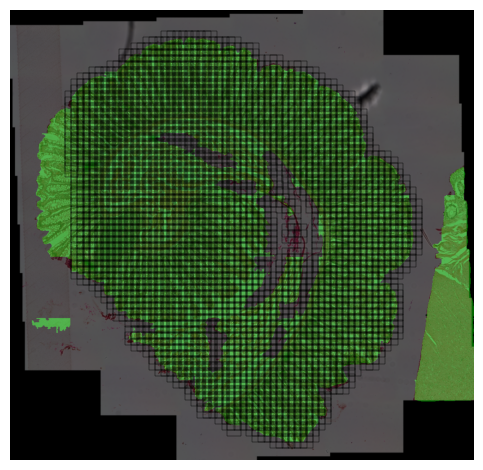

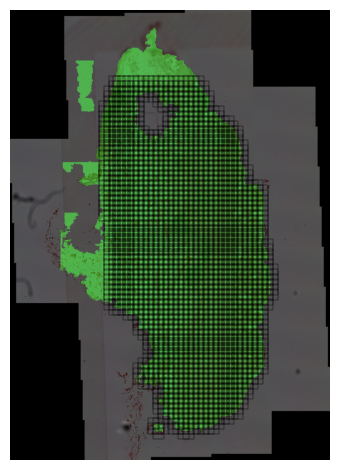

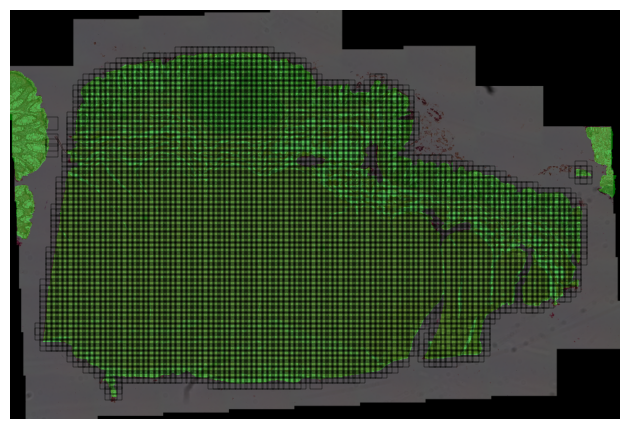

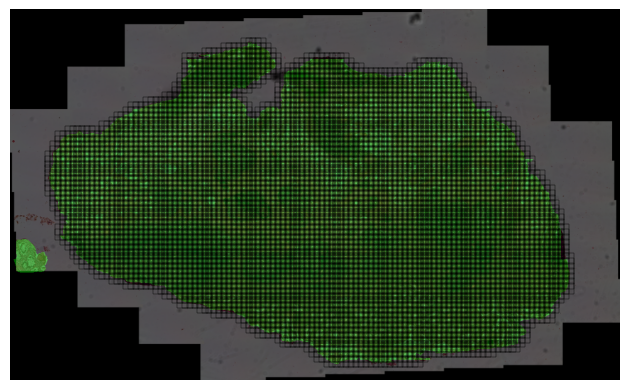

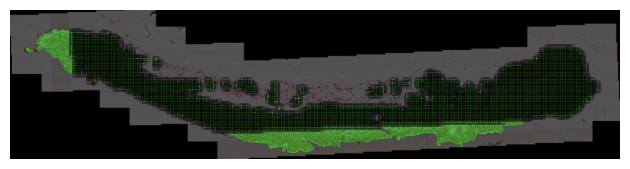

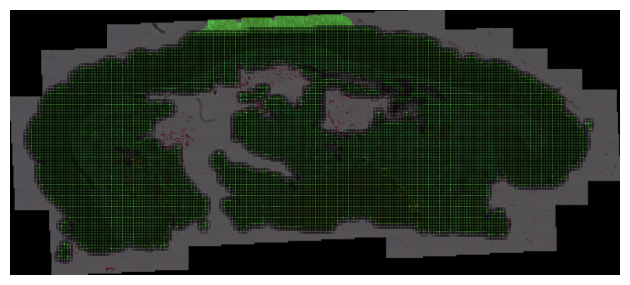

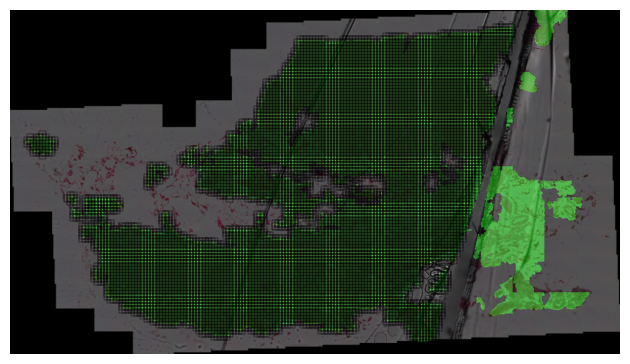

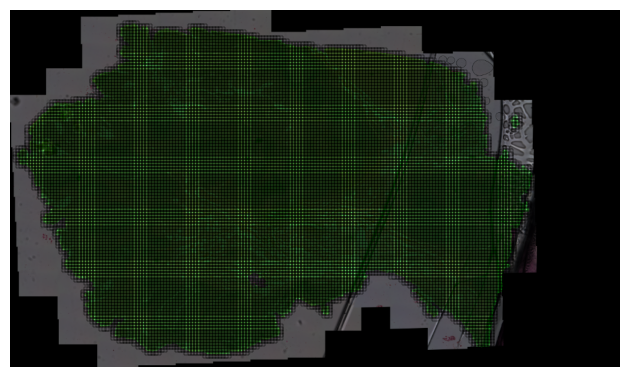

In [8]:
patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

[INFO] Auto-detected 7 sample folders: ['ROI1', 'ROI2', 'ROI3', 'ROI4', 'ROI5', 'ROI6', 'ROI7']


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43483325563202857
        'wsi' is <width=17305, height=16539, backend=CuImageWSI>
        'shapes': []
[INFO] ROI1: tissue_seg present = True


100%|██████████| 11235/11235 [01:02<00:00, 180.90it/s]


found 0 valid patches
[INFO] Patches saved for ROI1: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI1/patches/ROI1.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI1/patches_vis/ROI1_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4344276223626176
        'wsi' is <width=22676, height=11873, backend=CuImageWSI>
        'shapes': []
[INFO] ROI2: tissue_seg present = True


100%|██████████| 9394/9394 [00:53<00:00, 174.03it/s]


found 0 valid patches
[INFO] Patches saved for ROI2: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI2/patches/ROI2.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI2/patches_vis/ROI2_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43424436873240163
        'wsi' is <width=15550, height=12731, backend=CuImageWSI>
        'shapes': []
[INFO] ROI3: tissue_seg present = True


100%|██████████| 6048/6048 [00:33<00:00, 180.30it/s]


found 0 valid patches
[INFO] Patches saved for ROI3: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI3/patches/ROI3.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI3/patches_vis/ROI3_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43512933641298734
        'wsi' is <width=19736, height=16011, backend=CuImageWSI>
        'shapes': []
[INFO] ROI4: tissue_seg present = True


100%|██████████| 10500/10500 [01:01<00:00, 170.37it/s]


found 0 valid patches
[INFO] Patches saved for ROI4: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI4/patches/ROI4.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI4/patches_vis/ROI4_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4346128823579932
        'wsi' is <width=10488, height=12013, backend=CuImageWSI>
        'shapes': []
[INFO] ROI5: tissue_seg present = True


100%|██████████| 3582/3582 [00:21<00:00, 170.29it/s]


found 0 valid patches
[INFO] Patches saved for ROI5: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI5/patches/ROI5.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI5/patches_vis/ROI5_patch_vis.png
        'pixel_size' is 0.4357339146174697
        'wsi' is <width=11505, height=16363, backend=CuImageWSI>
        'shapes': []
[INFO] ROI6: tissue_seg present = True


100%|██████████| 6474/6474 [00:36<00:00, 176.96it/s]


found 0 valid patches
[INFO] Patches saved for ROI6: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI6/patches/ROI6.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI6/patches_vis/ROI6_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43486571487000075
        'wsi' is <width=17044, height=10800, backend=CuImageWSI>
        'shapes': []
[INFO] ROI7: tissue_seg present = True


100%|██████████| 7431/7431 [00:41<00:00, 178.42it/s]


found 0 valid patches
[INFO] Patches saved for ROI7: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI7/patches/ROI7.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/ROI7/patches_vis/ROI7_patch_vis.png


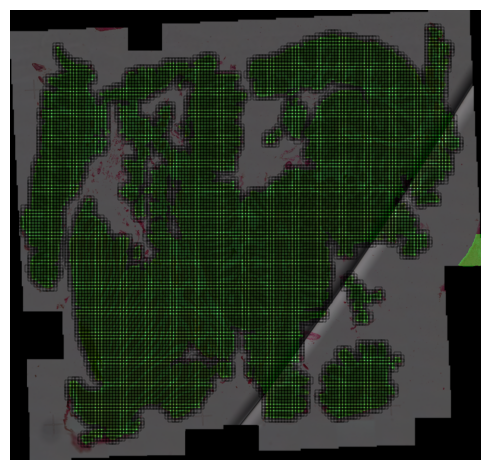

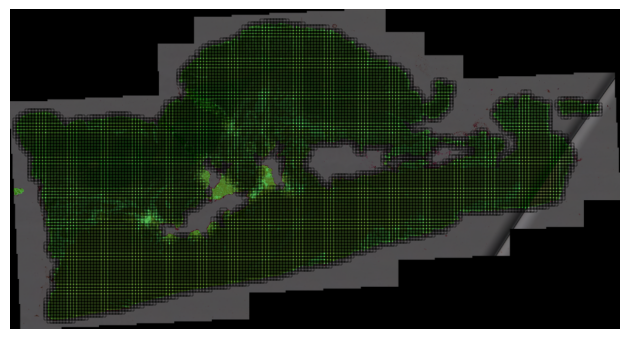

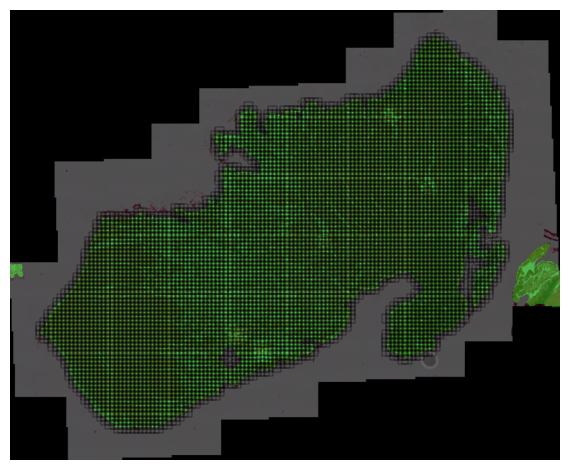

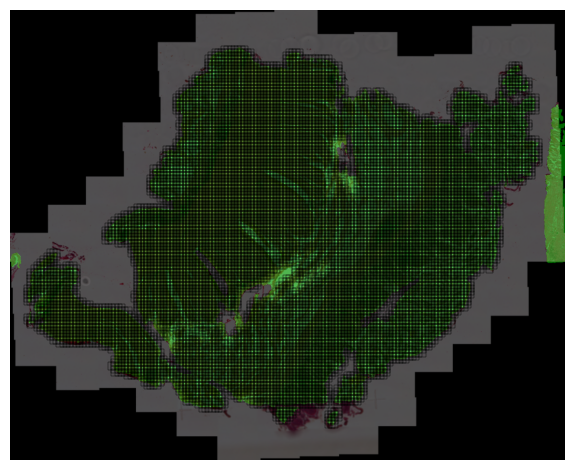

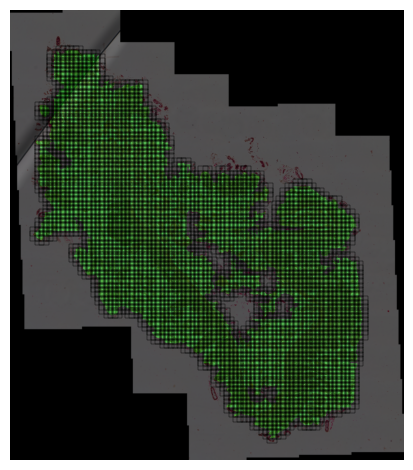

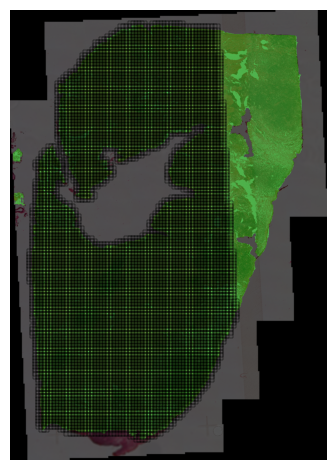

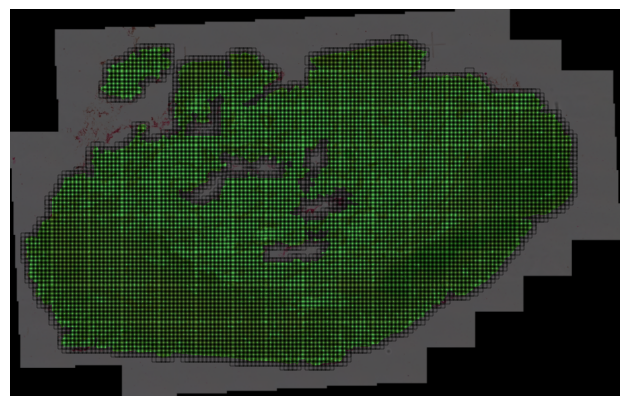

In [9]:
patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

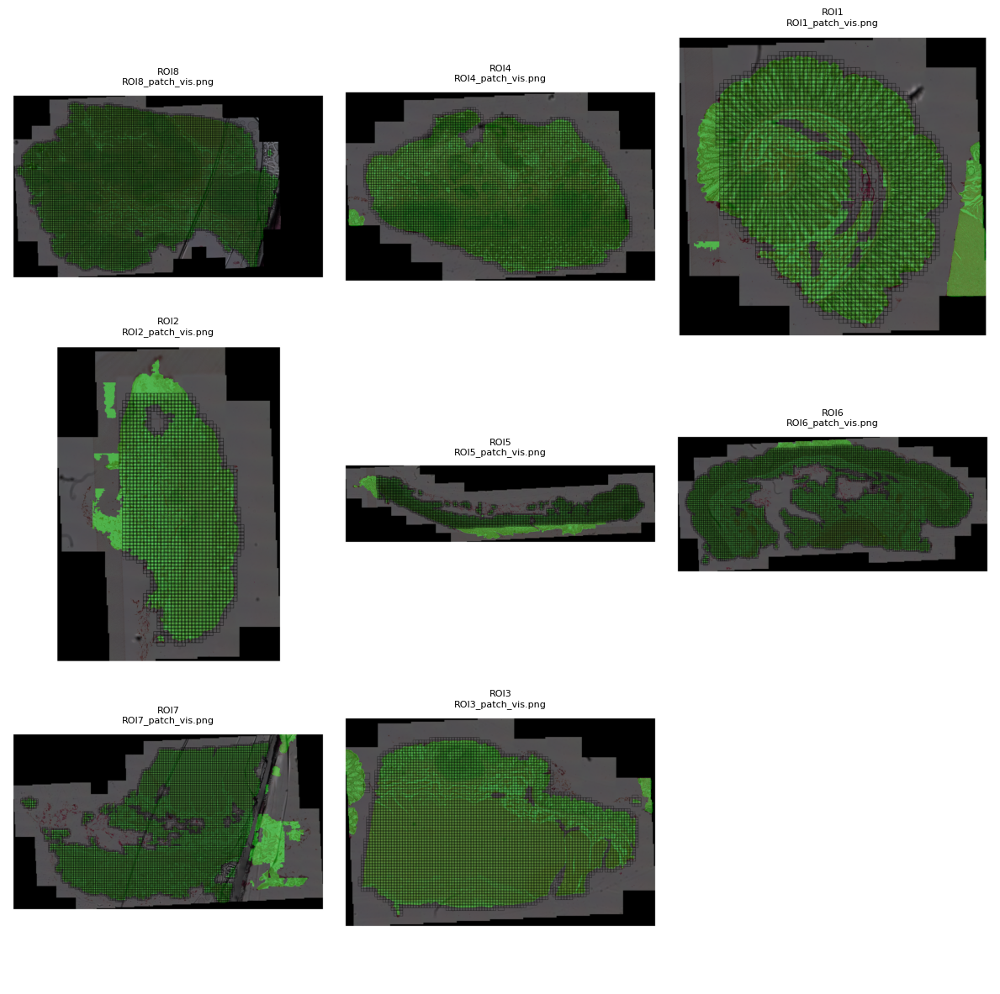

In [11]:
show_images("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1", subfolders=("patches_vis",))

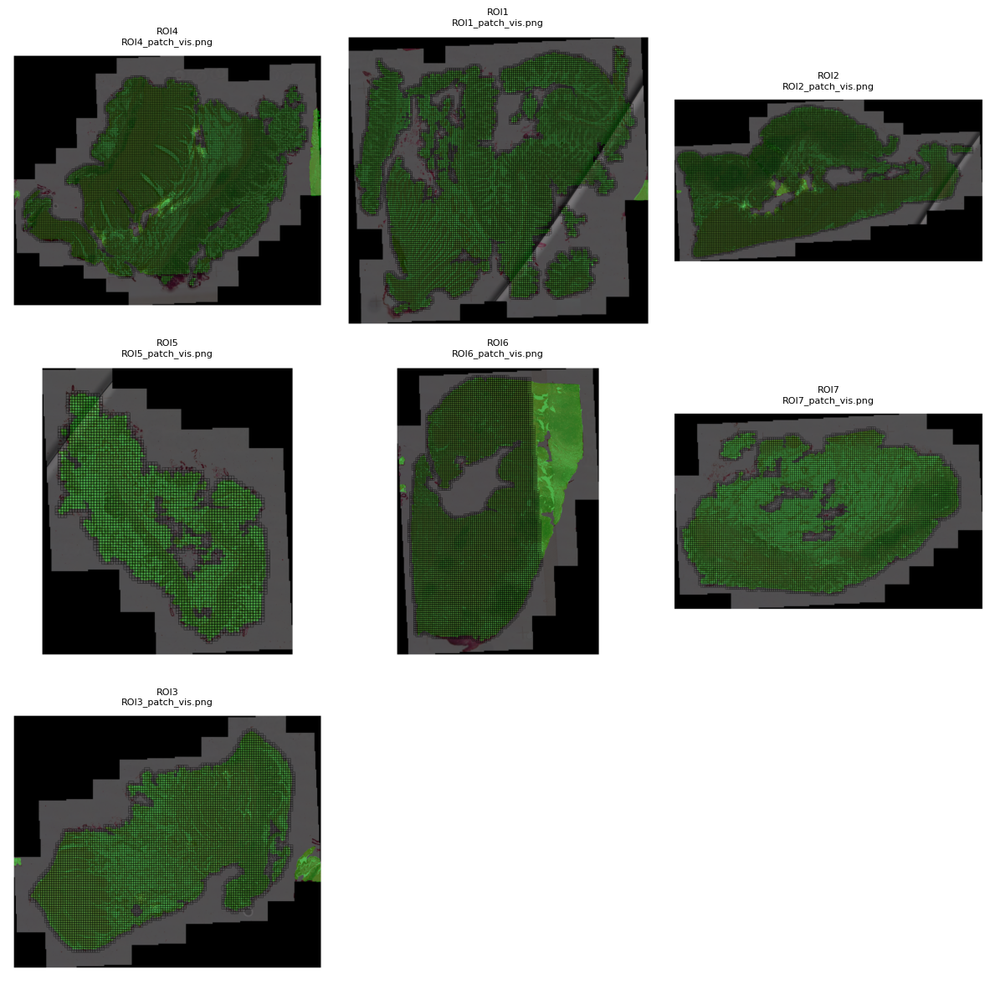

In [12]:
show_images("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2", subfolders=("patches_vis",))

In [17]:
df_counts = count_patches("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1", save_csv="patch_counts.csv")
df_counts = count_patches("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2", save_csv="patch_counts.csv")

  sample_id  num_patches
0      ROI1         2727
1      ROI2         1886
2      ROI3         4627
3      ROI4         5010
4      ROI5         3520
5      ROI6        10616
6      ROI7         8404
7      ROI8        13168

Total patches across all samples: 49958
[INFO] Saved counts to /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/patch_counts.csv
  sample_id  num_patches
0      ROI1        11235
1      ROI2         9394
2      ROI3         6048
3      ROI4        10500
4      ROI5         3582
5      ROI6         6474
6      ROI7         7431

Total patches across all samples: 54664
[INFO] Saved counts to /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide2/patch_counts.csv


Selected 25 patches (fallback used: False)


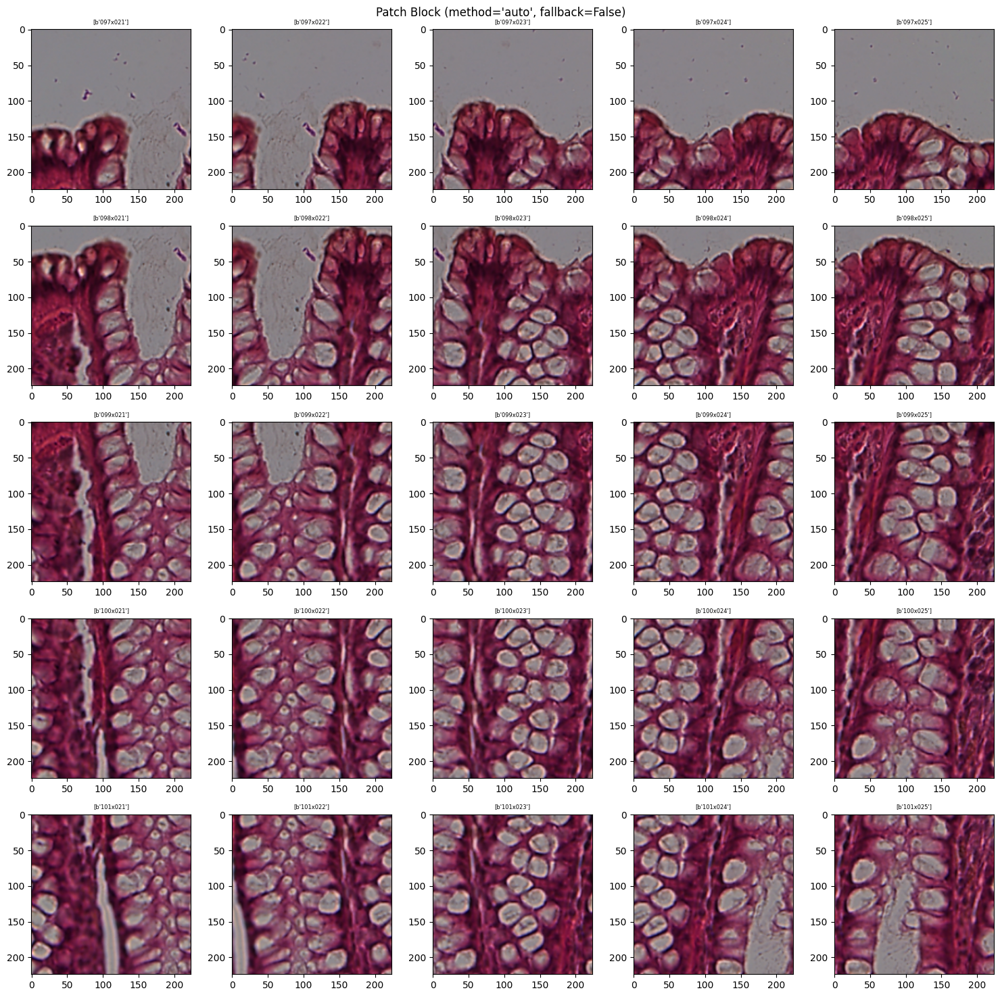

[INFO] fullres_size not provided; inferred from coords as (H_full=8315, W_full=7815). Pass fullres_size=(H,W) for exact scaling.


In [3]:
# paths
hest_root = Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI1")
h5_file   = hest_root / "patches" / "ROI1.h5"
jpeg_path = hest_root / "downscaled_fullres.jpeg"   # use this as the background (fast)

# simplest: let the function infer full-res dims from coords
visualise_patch_block(
    h5_file_path=h5_file,
    jpeg_path=jpeg_path,
    block_size=5,                 # e.g., 5x5 block
    highlight_color="yellow",
    max_display_side_px=2000
)

Loaded 2727 patches, showing first 25


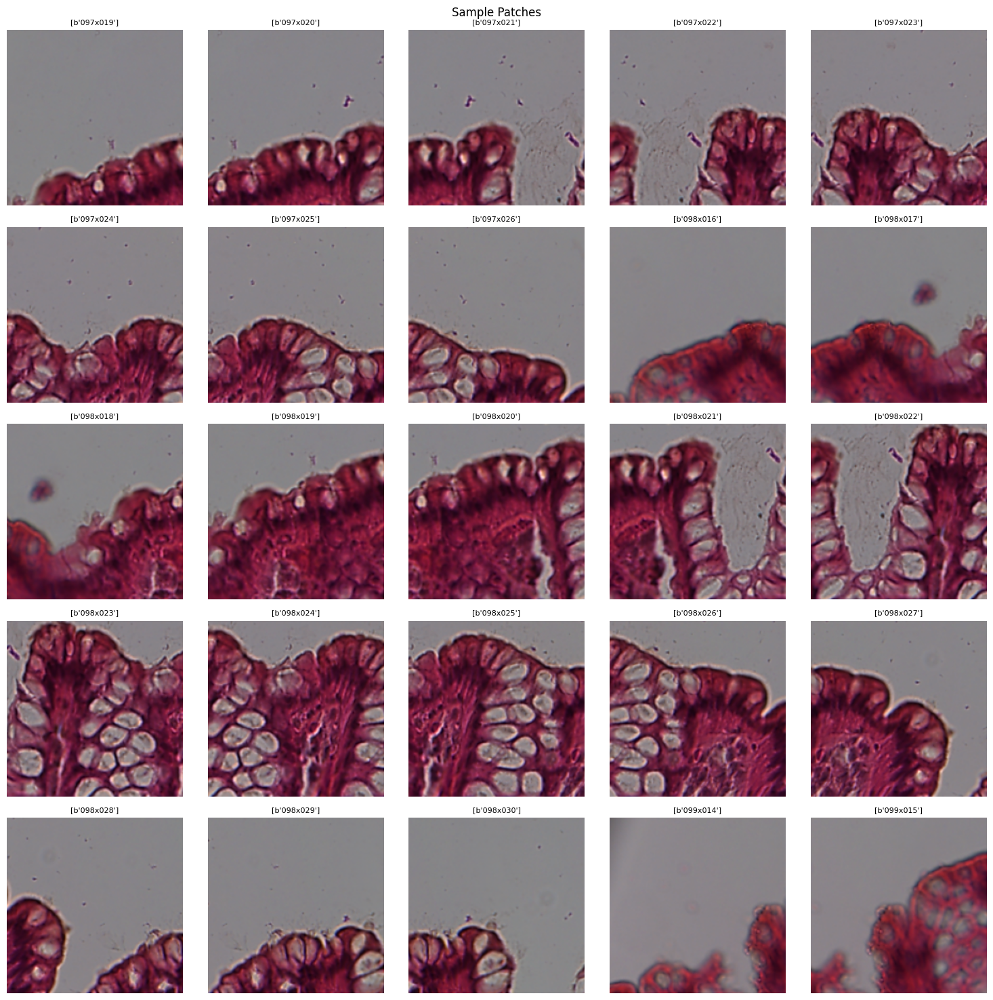

In [6]:
# function is defined in this notebook above
hest_root = "/project/simmons_hts/kxu/hest/data"
hest_root = Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um/slide1/ROI1")
h5_file   = hest_root / "patches" / "ROI1.h5"
wsi_image = Path(hest_root) / "aligned_fullres_HE.tif"  # downscaled WSI for visualization

visualise_first_n_patches(h5_file, wsi_path=wsi_image, max_patches=25)

### patching at 0.25 um/px (40x mag, patch size = 56 um, spot size = 50 um)

create a new folder to store these patches

kxu@imm-login1:/project/simmons_hts/kxu/hest/xenium_data$ cp -R XeniumPR1_50um XeniumPR1_50um_0.25_um_px

[INFO] Auto-detected 8 sample folders: ['ROI1', 'ROI2', 'ROI3', 'ROI4', 'ROI5', 'ROI6', 'ROI7', 'ROI8']


/home/k/kxu/.local/lib/python3.11/site-packages/hestcore/wsi.py:27: UserWarning: CuImage is not available. Ensure you have a GPU and cucim installed to use GPU acceleration.
  warnings.warn("CuImage is not available. Ensure you have a GPU and cucim installed to use GPU acceleration.")
/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4353514884015406
        'wsi' is <width=8851, height=8585, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI1: tissue_seg present = True


100%|██████████| 2603/2603 [00:16<00:00, 156.57it/s]


found 0 valid patches
[INFO] Patches saved for ROI1: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI1/patches/ROI1.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI1/patches_vis/ROI1_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43561023341205224
        'wsi' is <width=7408, height=10434, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI2: tissue_seg present = True


100%|██████████| 1838/1838 [00:12<00:00, 150.57it/s]


found 0 valid patches
[INFO] Patches saved for ROI2: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI2/patches/ROI2.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI2/patches_vis/ROI2_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4346822863887948
        'wsi' is <width=12994, height=8725, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI3: tissue_seg present = True


100%|██████████| 4502/4502 [00:29<00:00, 154.46it/s]


found 0 valid patches
[INFO] Patches saved for ROI3: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI3/patches/ROI3.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI3/patches_vis/ROI3_patch_vis.png
        'pixel_size' is 0.43509460497596525
        'wsi' is <width=14343, height=8724, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI4: tissue_seg present = True


100%|██████████| 4903/4903 [00:30<00:00, 162.58it/s]


found 0 valid patches
[INFO] Patches saved for ROI4: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI4/patches/ROI4.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI4/patches_vis/ROI4_patch_vis.png
        'pixel_size' is 0.4342285450650283
        'wsi' is <width=29752, height=7302, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI5: tissue_seg present = True


100%|██████████| 3289/3289 [00:24<00:00, 136.49it/s]


found 0 valid patches
[INFO] Patches saved for ROI5: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI5/patches/ROI5.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI5/patches_vis/ROI5_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.434453340495722
        'wsi' is <width=25467, height=11081, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI6: tissue_seg present = True


100%|██████████| 10205/10205 [01:05<00:00, 155.30it/s]


found 0 valid patches
[INFO] Patches saved for ROI6: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI6/patches/ROI6.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI6/patches_vis/ROI6_patch_vis.png
        'pixel_size' is 0.4338127352315242
        'wsi' is <width=22924, height=12938, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI7: tissue_seg present = True


100%|██████████| 8082/8082 [00:52<00:00, 155.15it/s]


found 0 valid patches
[INFO] Patches saved for ROI7: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI7/patches/ROI7.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI7/patches_vis/ROI7_patch_vis.png
        'pixel_size' is 0.4370543529121492
        'wsi' is <width=22816, height=13369, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI8: tissue_seg present = True


100%|██████████| 12945/12945 [01:16<00:00, 170.07it/s]


found 0 valid patches
[INFO] Patches saved for ROI8: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI8/patches/ROI8.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI8/patches_vis/ROI8_patch_vis.png
[INFO] Auto-detected 7 sample folders: ['ROI1', 'ROI2', 'ROI3', 'ROI4', 'ROI5', 'ROI6', 'ROI7']


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43483325563202857
        'wsi' is <width=17305, height=16539, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI1: tissue_seg present = True


100%|██████████| 10668/10668 [00:55<00:00, 191.40it/s]


found 0 valid patches
[INFO] Patches saved for ROI1: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI1/patches/ROI1.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI1/patches_vis/ROI1_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4344276223626176
        'wsi' is <width=22676, height=11873, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI2: tissue_seg present = True


100%|██████████| 9094/9094 [00:51<00:00, 176.93it/s]


found 0 valid patches
[INFO] Patches saved for ROI2: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI2/patches/ROI2.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI2/patches_vis/ROI2_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43424436873240163
        'wsi' is <width=15550, height=12731, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI3: tissue_seg present = True


100%|██████████| 5856/5856 [00:34<00:00, 171.14it/s]


found 0 valid patches
[INFO] Patches saved for ROI3: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI3/patches/ROI3.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI3/patches_vis/ROI3_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43512933641298734
        'wsi' is <width=19736, height=16011, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI4: tissue_seg present = True


100%|██████████| 10197/10197 [00:57<00:00, 176.61it/s]


found 0 valid patches
[INFO] Patches saved for ROI4: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI4/patches/ROI4.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI4/patches_vis/ROI4_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4346128823579932
        'wsi' is <width=10488, height=12013, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI5: tissue_seg present = True


100%|██████████| 3395/3395 [00:19<00:00, 177.23it/s]


found 0 valid patches
[INFO] Patches saved for ROI5: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI5/patches/ROI5.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI5/patches_vis/ROI5_patch_vis.png
        'pixel_size' is 0.4357339146174697
        'wsi' is <width=11505, height=16363, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI6: tissue_seg present = True


100%|██████████| 6312/6312 [00:35<00:00, 178.64it/s]


found 0 valid patches
[INFO] Patches saved for ROI6: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI6/patches/ROI6.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI6/patches_vis/ROI6_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43486571487000075
        'wsi' is <width=17044, height=10800, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI7: tissue_seg present = True


100%|██████████| 7186/7186 [00:42<00:00, 170.07it/s]


found 0 valid patches
[INFO] Patches saved for ROI7: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI7/patches/ROI7.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/ROI7/patches_vis/ROI7_patch_vis.png


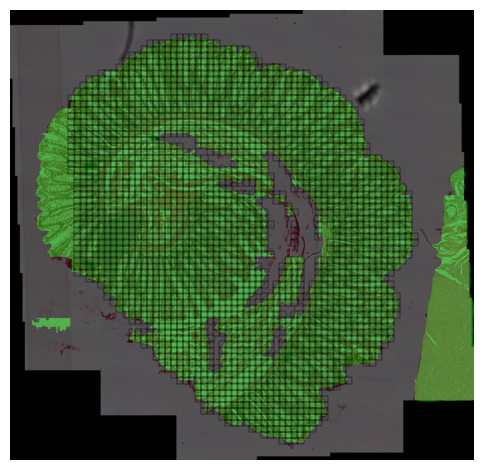

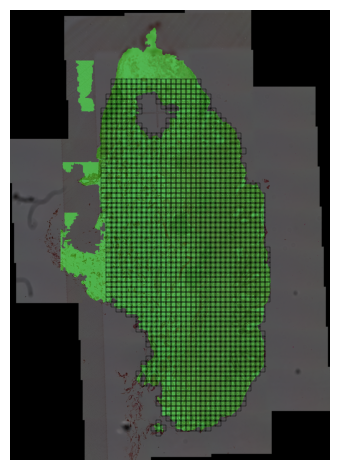

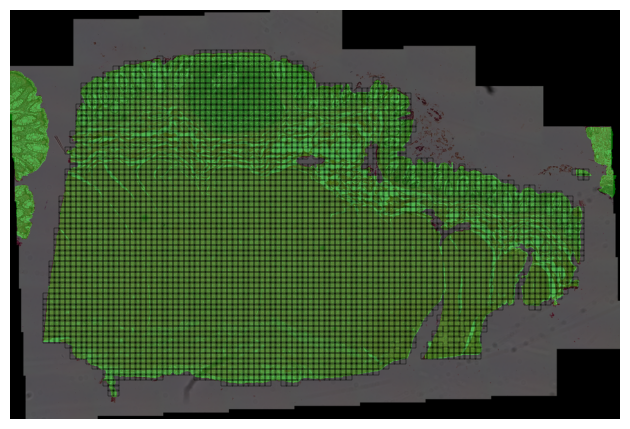

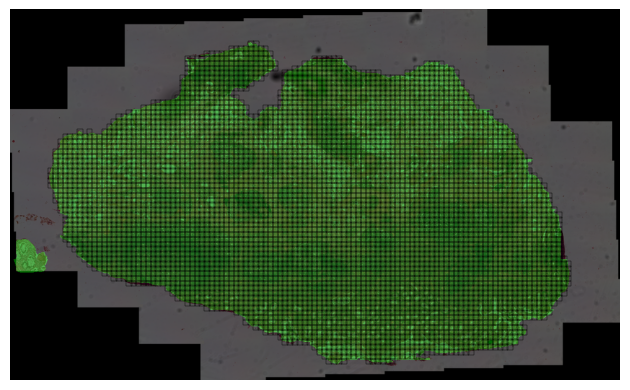

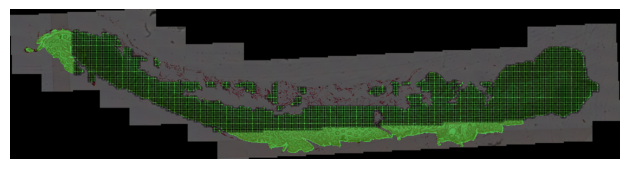

...

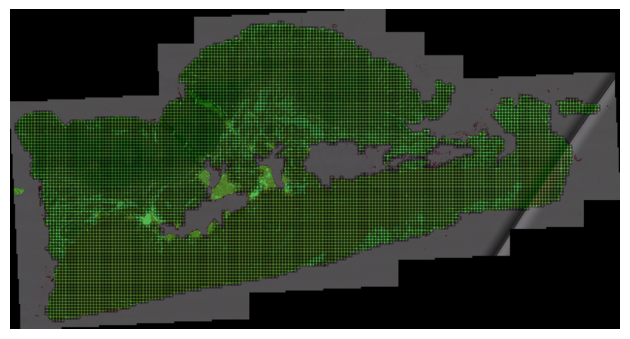

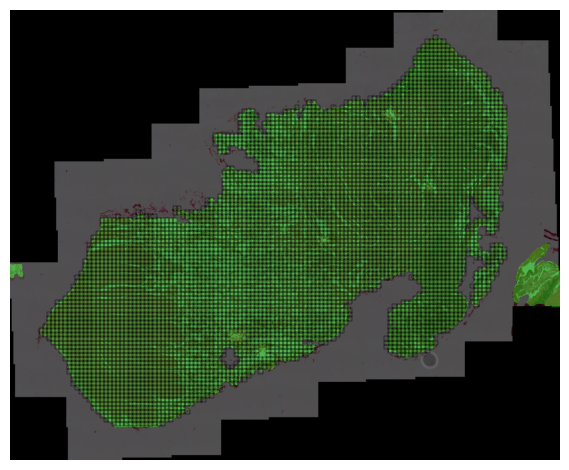

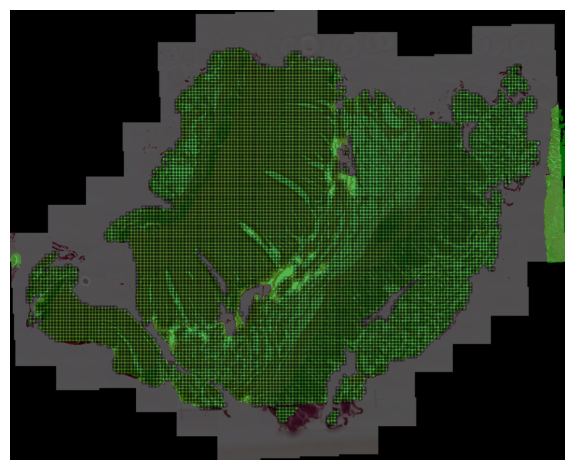

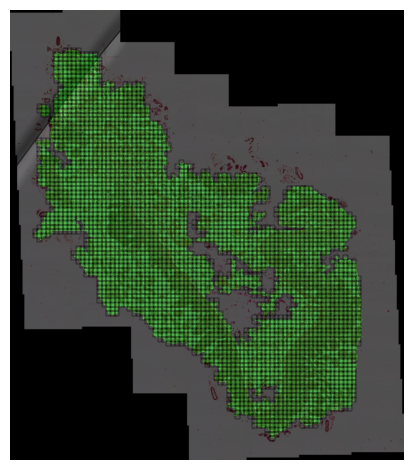

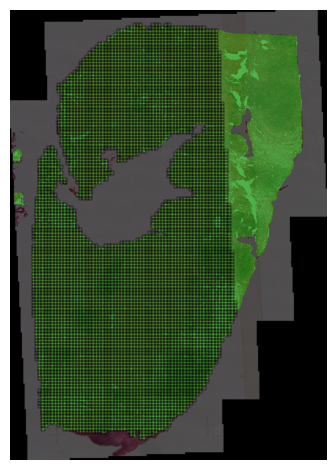

In [ ]:
patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.25,
    threshold = 0.15
)

patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide2/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.25,
    threshold = 0.15
)

Selected 25 patches (fallback used: False)


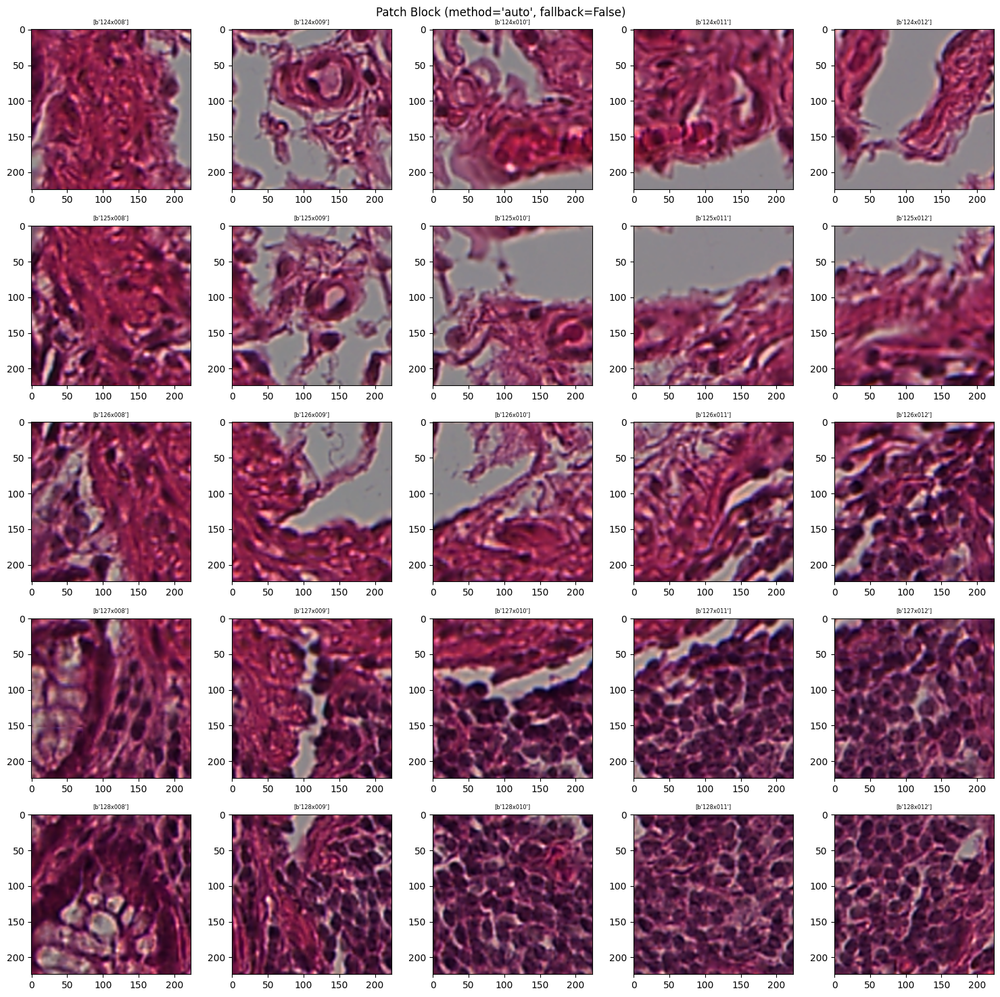

[INFO] fullres_size not provided; inferred from coords as (H_full=8379, W_full=7879). Pass fullres_size=(H,W) for exact scaling.


In [3]:
# paths
hest_root = Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI1")
h5_file   = hest_root / "patches" / "ROI1.h5"
jpeg_path = hest_root / "downscaled_fullres.jpeg"   # use this as the background (fast)

# simplest: let the function infer full-res dims from coords
visualise_patch_block(
    h5_file_path=h5_file,
    jpeg_path=jpeg_path,
    block_size=5,                 # e.g., 5x5 block
    highlight_color="yellow",
    max_display_side_px=2000
)

Loaded 2603 patches, showing first 25


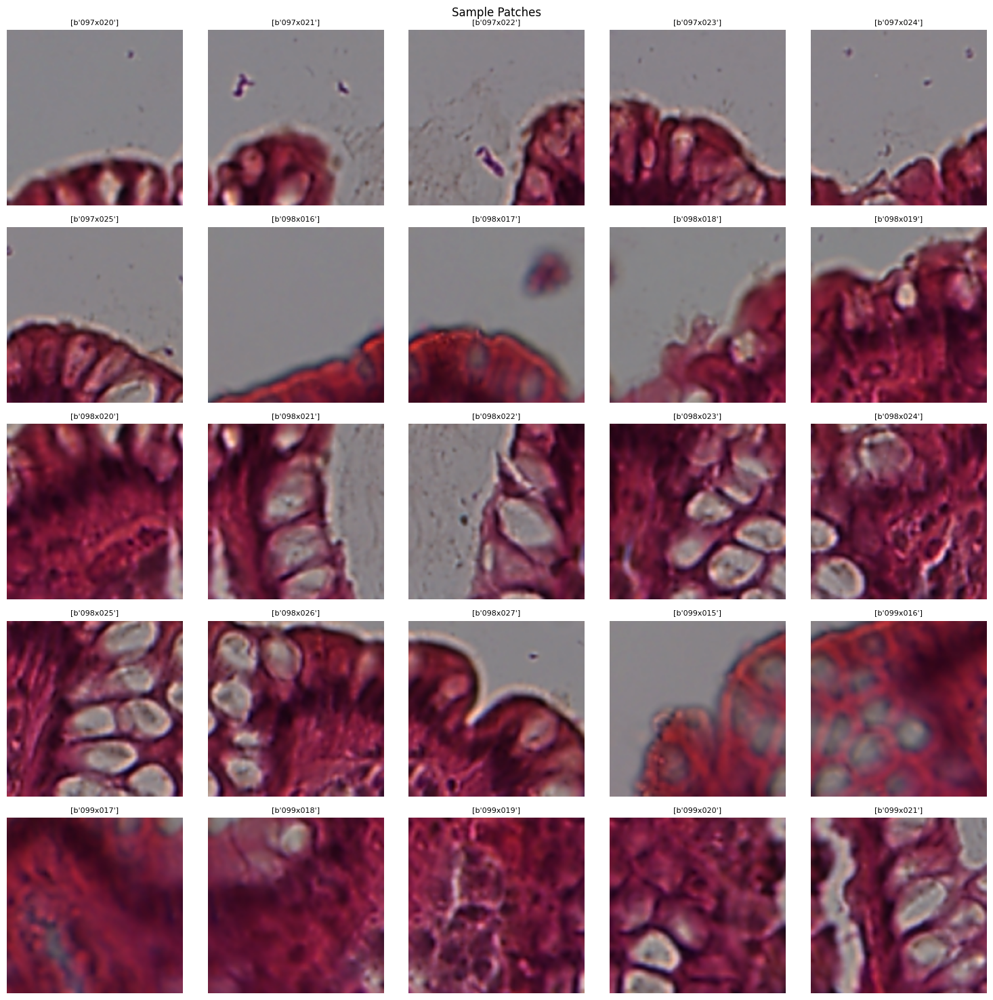

In [4]:
# function is defined in this notebook above
hest_root = "/project/simmons_hts/kxu/hest/data"
hest_root = Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_50um_0.25_um_px/slide1/ROI1")
h5_file   = hest_root / "patches" / "ROI1.h5"
wsi_image = Path(hest_root) / "aligned_fullres_HE.tif"  # downscaled WSI for visualization

visualise_first_n_patches(h5_file, wsi_path=wsi_image, max_patches=25)

# Patch XeniumPR1_25um samples

### @0.125 um/pixel

These patches are in 0.125 um/pixel (which is 80x magnification). Patch size corresponds to spot size.

[INFO] Auto-detected 8 sample folders: ['ROI1', 'ROI2', 'ROI3', 'ROI4', 'ROI5', 'ROI6', 'ROI7', 'ROI8']


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4353514884015406
        'wsi' is <width=8851, height=8585, backend=CuImageWSI>
        'shapes': []
[INFO] ROI1: tissue_seg present = True


100%|██████████| 9950/9950 [00:41<00:00, 242.00it/s]


found 0 valid patches
[INFO] Patches saved for ROI1: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI1/patches/ROI1.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI1/patches_vis/ROI1_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43561023341205224
        'wsi' is <width=7408, height=10434, backend=CuImageWSI>
        'shapes': []
[INFO] ROI2: tissue_seg present = True


100%|██████████| 7130/7130 [00:30<00:00, 237.42it/s]


found 0 valid patches
[INFO] Patches saved for ROI2: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI2/patches/ROI2.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI2/patches_vis/ROI2_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4346822863887948
        'wsi' is <width=12994, height=8725, backend=CuImageWSI>
        'shapes': []
[INFO] ROI3: tissue_seg present = True


100%|██████████| 17368/17368 [01:11<00:00, 242.63it/s]


found 0 valid patches
[INFO] Patches saved for ROI3: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI3/patches/ROI3.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI3/patches_vis/ROI3_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43509460497596525
        'wsi' is <width=14343, height=8724, backend=CuImageWSI>
        'shapes': []
[INFO] ROI4: tissue_seg present = True


100%|██████████| 19360/19360 [01:20<00:00, 241.10it/s]


found 0 valid patches
[INFO] Patches saved for ROI4: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI4/patches/ROI4.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI4/patches_vis/ROI4_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4342285450650283
        'wsi' is <width=29752, height=7302, backend=CuImageWSI>
        'shapes': []
[INFO] ROI5: tissue_seg present = True


100%|██████████| 12449/12449 [00:53<00:00, 234.61it/s]


found 0 valid patches
[INFO] Patches saved for ROI5: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI5/patches/ROI5.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI5/patches_vis/ROI5_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.434453340495722
        'wsi' is <width=25467, height=11081, backend=CuImageWSI>
        'shapes': []
[INFO] ROI6: tissue_seg present = True


100%|██████████| 39153/39153 [02:40<00:00, 243.75it/s]


found 0 valid patches
[INFO] Patches saved for ROI6: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI6/patches/ROI6.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI6/patches_vis/ROI6_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4338127352315242
        'wsi' is <width=22924, height=12938, backend=CuImageWSI>
        'shapes': []
[INFO] ROI7: tissue_seg present = True


100%|██████████| 31342/31342 [02:11<00:00, 238.79it/s]


found 0 valid patches
[INFO] Patches saved for ROI7: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI7/patches/ROI7.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI7/patches_vis/ROI7_patch_vis.png
        'pixel_size' is 0.4370543529121492
        'wsi' is <width=22816, height=13369, backend=CuImageWSI>
        'shapes': []
[INFO] ROI8: tissue_seg present = True


100%|██████████| 51260/51260 [03:29<00:00, 245.19it/s]


found 0 valid patches
[INFO] Patches saved for ROI8: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI8/patches/ROI8.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI8/patches_vis/ROI8_patch_vis.png


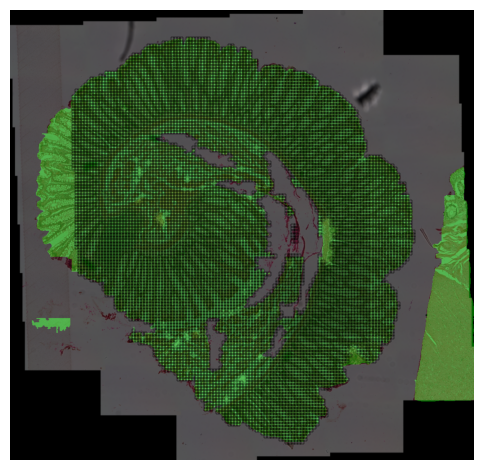

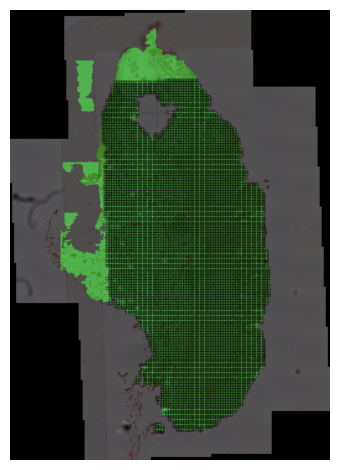

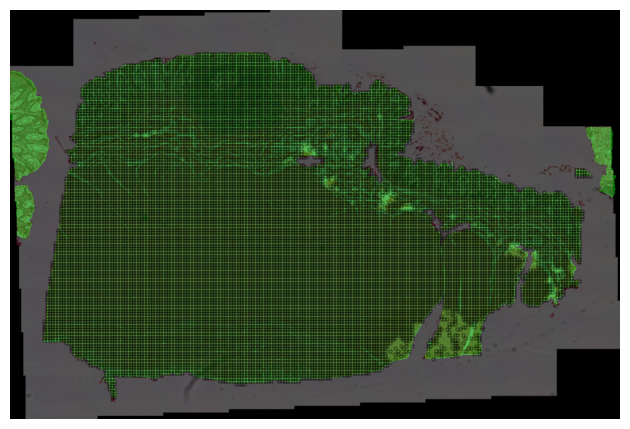

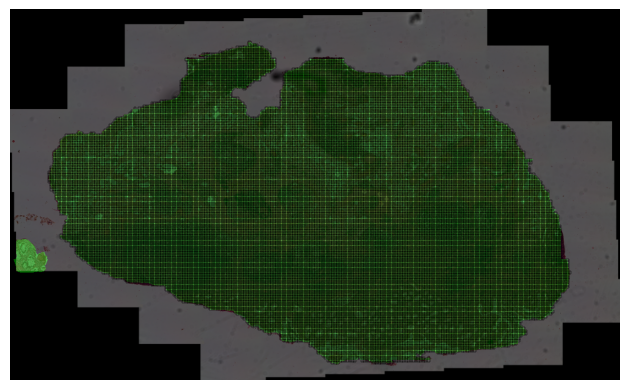

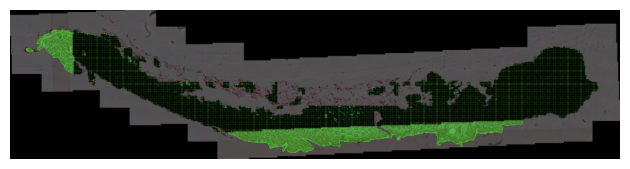

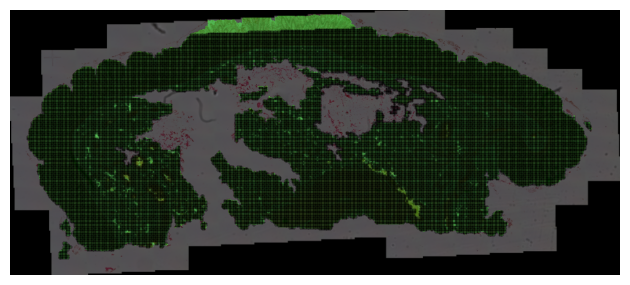

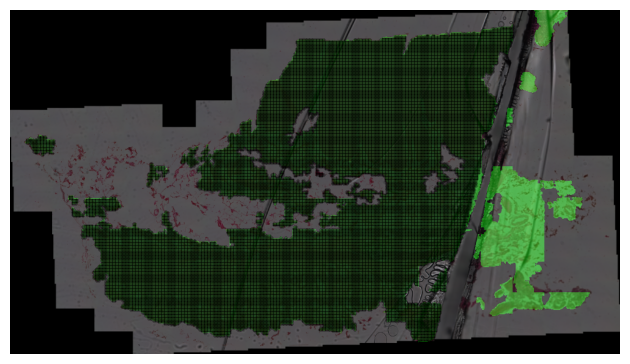

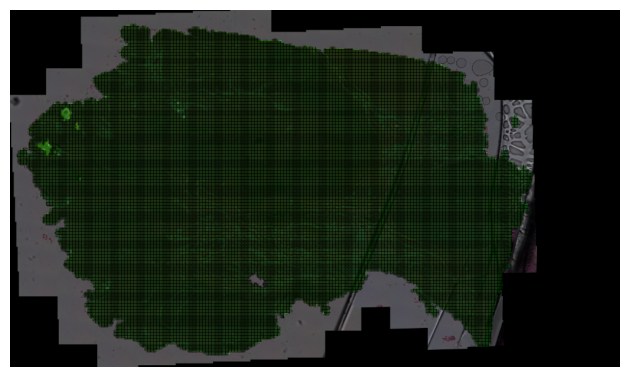

In [5]:
patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um_0.125_um_px/slide1/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.125,
    threshold = 0.15
)

In [ ]:
patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um_0.125_um_px/slide2/"),
    target_patch_size = 224,
    target_pixel_size = 0.125,
    threshold = 0.15
)

[INFO] Auto-detected 7 sample folders: ['ROI1', 'ROI2', 'ROI3', 'ROI4', 'ROI5', 'ROI6', 'ROI7']


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43483325563202857
        'wsi' is <width=17305, height=16539, backend=CuImageWSI>
        'shapes': []
[INFO] ROI1: tissue_seg present = True


100%|██████████| 40858/40858 [02:46<00:00, 245.99it/s]


found 0 valid patches
[INFO] Patches saved for ROI1: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI1/patches/ROI1.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI1/patches_vis/ROI1_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4344276223626176
        'wsi' is <width=22676, height=11873, backend=CuImageWSI>
        'shapes': []
[INFO] ROI2: tissue_seg present = True


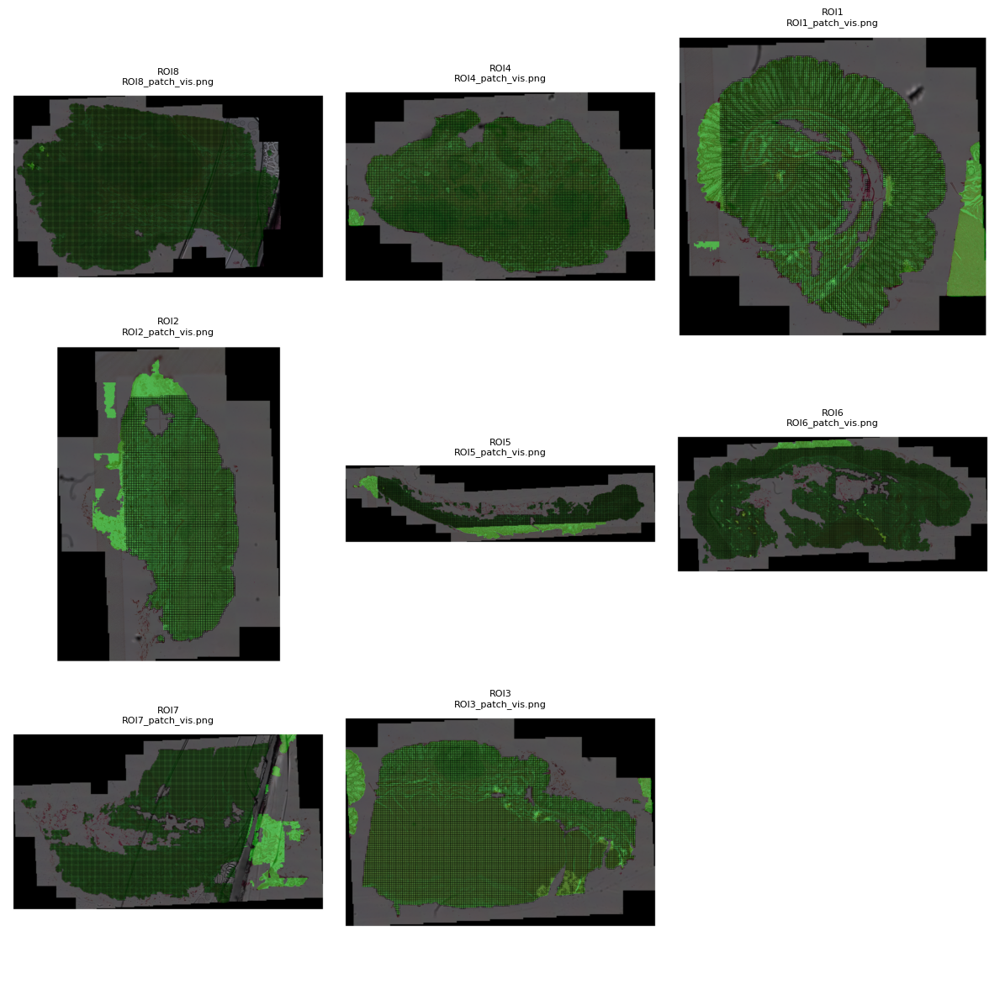

In [2]:
show_images("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um_0.125_um_px/slide1", subfolders=("patches_vis",))

In [ ]:
show_images("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um_0.125_um_px/slide2", subfolders=("patches_vis",))

### @at original magnification (0.5 um/px)

These patches are in 0.5 um/pixel (which is 20x magnification). Patch size is 8 times spot size.

In [11]:
patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/"),
    ids=['ROI6', 'ROI7', 'ROI8'],
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

/package/python-cbrg/current/3.11.14/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:428: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.434453340495722
        'wsi' is <width=25467, height=11081, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI6: tissue_seg present = True


100%|██████████| 33672/33672 [03:32<00:00, 158.75it/s]


found 0 valid patches
[INFO] Patches saved for ROI7: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI7/patches/ROI7.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide1/ROI7/patches_vis/ROI7_patch_vis.png
        'pixel_size' is 0.4370543529121492
        'wsi' is <width=22816, height=13369, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI8: tissue_seg present = True


 25%|██▍       | 13095/52584 [01:45<05:58, 110.17it/s]IOPub message rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_msg_rate_limit`.

Current values:
NotebookApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
NotebookApp.rate_limit_window=3.0 (secs)



[INFO] Auto-detected 7 sample folders: ['ROI1', 'ROI2', 'ROI3', 'ROI4', 'ROI5', 'ROI6', 'ROI7']


/package/python-cbrg/current/3.11.14/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:428: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43483325563202857
        'wsi' is <width=17305, height=16539, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI1: tissue_seg present = True


100%|██████████| 43926/43926 [05:45<00:00, 126.99it/s]


found 0 valid patches
[INFO] Patches saved for ROI1: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI1/patches/ROI1.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI1/patches_vis/ROI1_patch_vis.png


/package/python-cbrg/current/3.11.14/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:428: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4344276223626176
        'wsi' is <width=22676, height=11873, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI2: tissue_seg present = True


100%|██████████| 36806/36806 [04:46<00:00, 128.63it/s]


found 0 valid patches
[INFO] Patches saved for ROI2: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI2/patches/ROI2.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI2/patches_vis/ROI2_patch_vis.png


/package/python-cbrg/current/3.11.14/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:428: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43424436873240163
        'wsi' is <width=15550, height=12731, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI3: tissue_seg present = True


100%|██████████| 23628/23628 [02:50<00:00, 138.94it/s]


found 0 valid patches
[INFO] Patches saved for ROI3: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI3/patches/ROI3.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI3/patches_vis/ROI3_patch_vis.png


/package/python-cbrg/current/3.11.14/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:428: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43512933641298734
        'wsi' is <width=19736, height=16011, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI4: tissue_seg present = True


100%|██████████| 40698/40698 [05:44<00:00, 118.11it/s]


found 0 valid patches
[INFO] Patches saved for ROI4: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI4/patches/ROI4.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI4/patches_vis/ROI4_patch_vis.png


/package/python-cbrg/current/3.11.14/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:428: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4346128823579932
        'wsi' is <width=10488, height=12013, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI5: tissue_seg present = True


100%|██████████| 14150/14150 [01:57<00:00, 120.93it/s]


found 0 valid patches
[INFO] Patches saved for ROI5: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI5/patches/ROI5.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI5/patches_vis/ROI5_patch_vis.png


/package/python-cbrg/current/3.11.14/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:428: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.4357339146174697
        'wsi' is <width=11505, height=16363, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI6: tissue_seg present = True


100%|██████████| 25561/25561 [03:36<00:00, 118.11it/s]


found 0 valid patches
[INFO] Patches saved for ROI6: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI6/patches/ROI6.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI6/patches_vis/ROI6_patch_vis.png


/package/python-cbrg/current/3.11.14/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:428: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.43486571487000075
        'wsi' is <width=17044, height=10800, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI7: tissue_seg present = True


100%|██████████| 27676/27676 [03:01<00:00, 152.67it/s]


found 0 valid patches
[INFO] Patches saved for ROI7: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI7/patches/ROI7.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/ROI7/patches_vis/ROI7_patch_vis.png


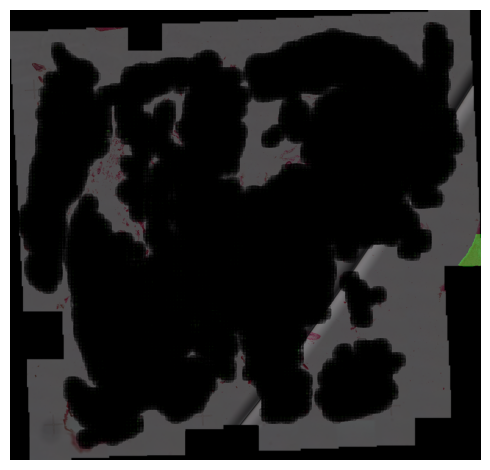

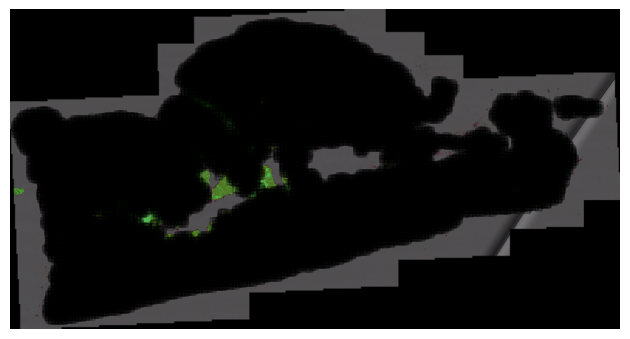

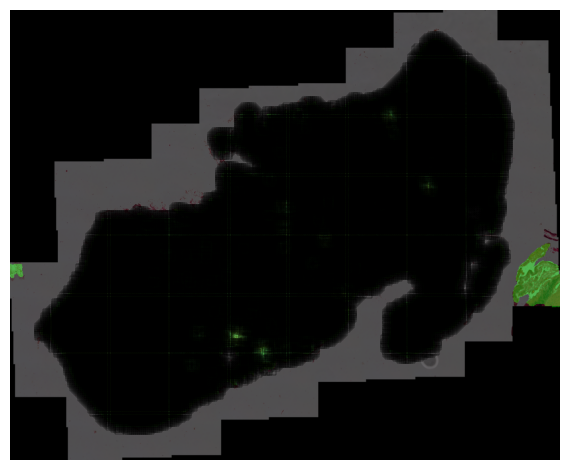

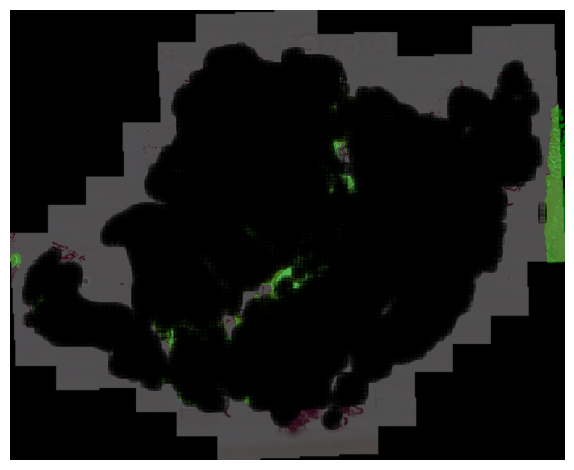

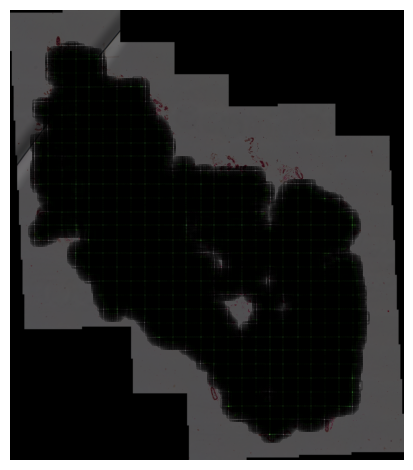

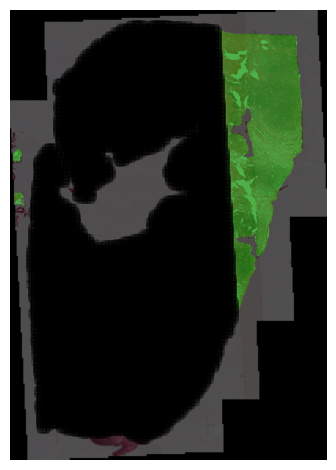

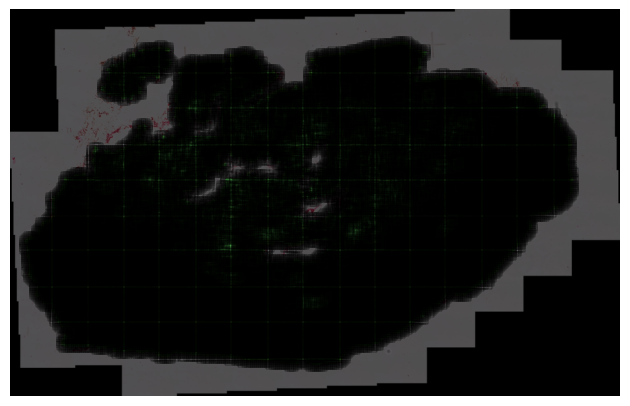

In [10]:
patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR1_25um/slide2/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

# XeniumPR2

### patching at 0.5 um/px (20x mag, patch size = 112 um, spot size = 100 um)

[INFO] Auto-detected 8 sample folders: ['ROI1', 'ROI2', 'ROI3', 'ROI4', 'ROI5', 'ROI6', 'ROI7', 'ROI8']
        'pixel_size' is 0.22046996430606813
        'wsi' is <width=36154, height=29248, backend=CuImageWSI>
        'shapes': []
[INFO] ROI1: tissue_seg present = True


100%|██████████| 2850/2850 [00:19<00:00, 148.64it/s]


found 0 valid patches
[INFO] Patches saved for ROI1: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI1/patches/ROI1.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI1/patches_vis/ROI1_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.22044341145869342
        'wsi' is <width=40436, height=27095, backend=CuImageWSI>
        'shapes': []
[INFO] ROI2: tissue_seg present = True


100%|██████████| 2352/2352 [00:15<00:00, 152.80it/s]


found 0 valid patches
[INFO] Patches saved for ROI2: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI2/patches/ROI2.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI2/patches_vis/ROI2_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.22042490374755971
        'wsi' is <width=41880, height=17378, backend=CuImageWSI>
        'shapes': []
[INFO] ROI3: tissue_seg present = True


100%|██████████| 1597/1597 [00:10<00:00, 152.34it/s]


found 0 valid patches
[INFO] Patches saved for ROI3: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI3/patches/ROI3.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI3/patches_vis/ROI3_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.22042490374755971
        'wsi' is <width=41880, height=17378, backend=CuImageWSI>
        'shapes': []
[INFO] ROI4: tissue_seg present = True


100%|██████████| 1592/1592 [00:10<00:00, 151.26it/s]


found 0 valid patches
[INFO] Patches saved for ROI4: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI4/patches/ROI4.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI4/patches_vis/ROI4_patch_vis.png
        'pixel_size' is 0.22044738679715123
        'wsi' is <width=39000, height=32472, backend=CuImageWSI>
        'shapes': []
[INFO] ROI5: tissue_seg present = True


100%|██████████| 2725/2725 [00:18<00:00, 146.52it/s]


found 0 valid patches
[INFO] Patches saved for ROI5: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI5/patches/ROI5.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI5/patches_vis/ROI5_patch_vis.png
        'pixel_size' is 0.22049483980597748
        'wsi' is <width=18874, height=17384, backend=CuImageWSI>
        'shapes': []
[INFO] ROI6: tissue_seg present = True


100%|██████████| 720/720 [00:04<00:00, 153.26it/s]


found 0 valid patches
[INFO] Patches saved for ROI6: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI6/patches/ROI6.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI6/patches_vis/ROI6_patch_vis.png
        'pixel_size' is 0.22050080354355434
        'wsi' is <width=21763, height=20608, backend=CuImageWSI>
        'shapes': []
[INFO] ROI7: tissue_seg present = True


100%|██████████| 565/565 [00:03<00:00, 153.40it/s]


found 0 valid patches
[INFO] Patches saved for ROI7: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI7/patches/ROI7.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI7/patches_vis/ROI7_patch_vis.png
        'pixel_size' is 0.22047194943862095
        'wsi' is <width=28979, height=37863, backend=CuImageWSI>
        'shapes': []
[INFO] ROI8: tissue_seg present = True


100%|██████████| 1362/1362 [00:09<00:00, 139.12it/s]


found 0 valid patches
[INFO] Patches saved for ROI8: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI8/patches/ROI8.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/ROI8/patches_vis/ROI8_patch_vis.png


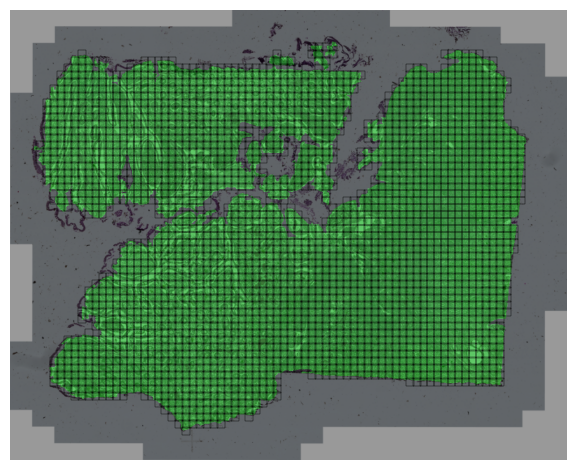

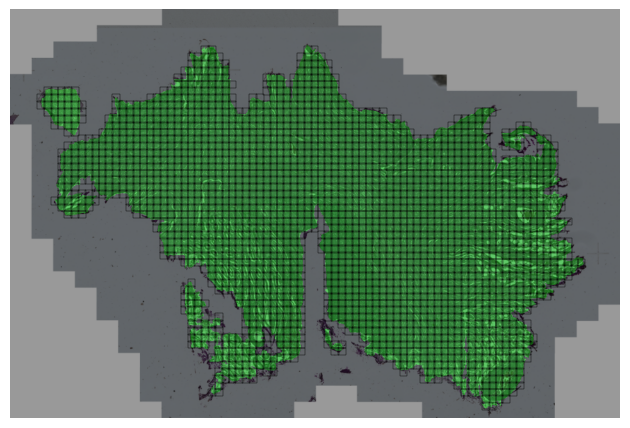

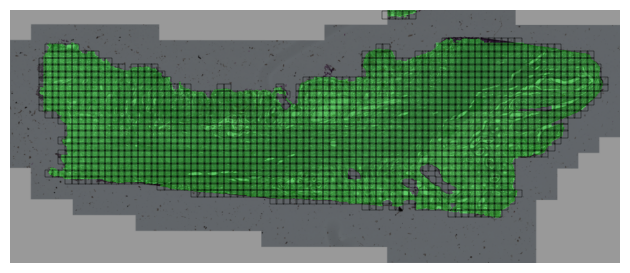

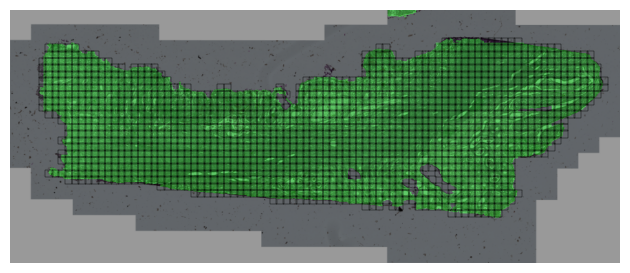

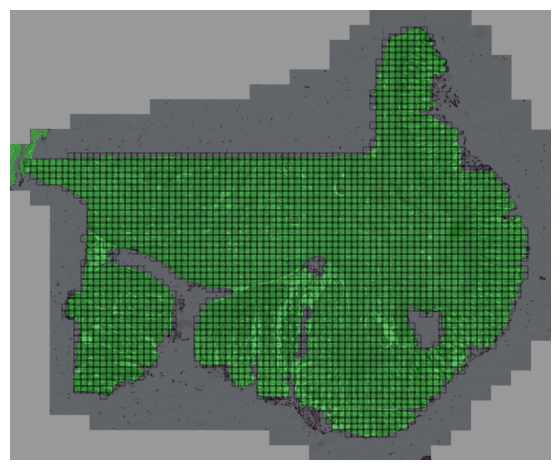

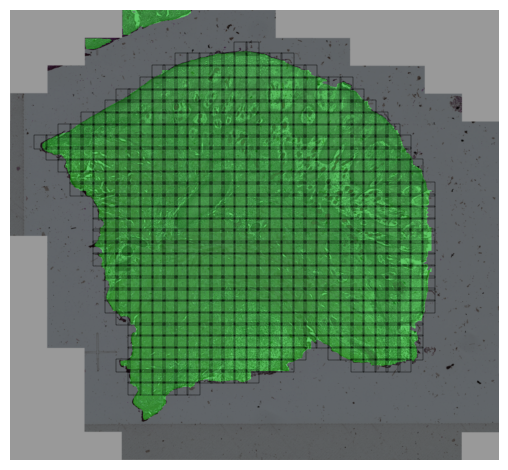

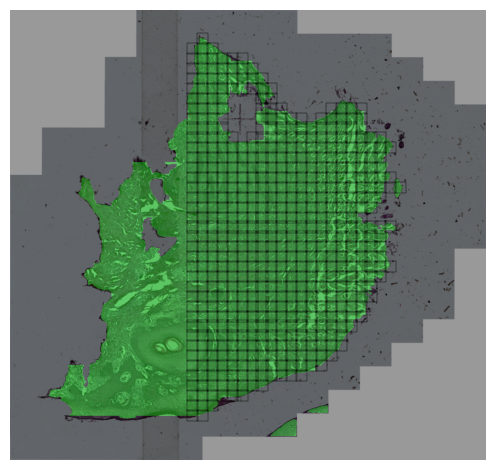

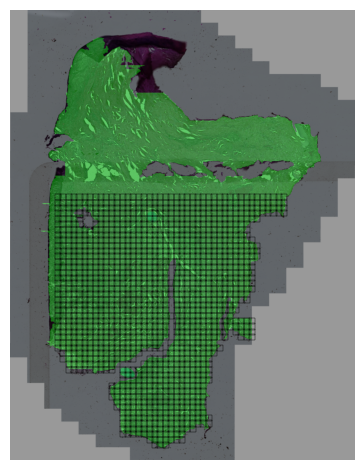

In [2]:
patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR2/slide1/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

# XeniumPR3
### patching at 0.5 um/px (20x mag, patch size = 112 um, spot size = 100 um)


[INFO] Auto-detected 8 sample folders: ['ROI1', 'ROI2', 'ROI3', 'ROI4', 'ROI5', 'ROI6', 'ROI7', 'ROI8']
        'pixel_size' is 0.22048850953081675
        'wsi' is <width=18919, height=47567, backend=CuImageWSI>
        'shapes': []
[INFO] ROI1: tissue_seg present = True


100%|██████████| 2625/2625 [00:17<00:00, 147.97it/s]


found 0 valid patches
[INFO] Patches saved for ROI1: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI1/patches/ROI1.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI1/patches_vis/ROI1_patch_vis.png
        'pixel_size' is 0.22066720343864732
        'wsi' is <width=15989, height=16316, backend=CuImageWSI>
        'shapes': []
[INFO] ROI2: tissue_seg present = True


100%|██████████| 672/672 [00:04<00:00, 154.55it/s]


found 0 valid patches
[INFO] Patches saved for ROI2: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI2/patches/ROI2.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI2/patches_vis/ROI2_patch_vis.png
        'pixel_size' is 0.22044554500792804
        'wsi' is <width=24646, height=28173, backend=CuImageWSI>
        'shapes': []
[INFO] ROI3: tissue_seg present = True


100%|██████████| 2044/2044 [00:13<00:00, 146.63it/s]


found 0 valid patches
[INFO] Patches saved for ROI3: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI3/patches/ROI3.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI3/patches_vis/ROI3_patch_vis.png
        'pixel_size' is 0.22041720307711582
        'wsi' is <width=36130, height=22770, backend=CuImageWSI>
        'shapes': []
[INFO] ROI4: tissue_seg present = True


100%|██████████| 2045/2045 [00:13<00:00, 147.81it/s]


found 0 valid patches
[INFO] Patches saved for ROI4: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI4/patches/ROI4.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI4/patches_vis/ROI4_patch_vis.png
        'pixel_size' is 0.2204176453879182
        'wsi' is <width=26068, height=24940, backend=CuImageWSI>
        'shapes': []
[INFO] ROI5: tissue_seg present = True


100%|██████████| 1476/1476 [00:09<00:00, 153.26it/s]


found 0 valid patches
[INFO] Patches saved for ROI5: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI5/patches/ROI5.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI5/patches_vis/ROI5_patch_vis.png
        'pixel_size' is 0.2204484764315189
        'wsi' is <width=21779, height=42164, backend=CuImageWSI>
        'shapes': []
[INFO] ROI6: tissue_seg present = True


100%|██████████| 2054/2054 [00:15<00:00, 136.80it/s]


found 0 valid patches
[INFO] Patches saved for ROI6: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI6/patches/ROI6.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI6/patches_vis/ROI6_patch_vis.png
        'pixel_size' is 0.22043846650257393
        'wsi' is <width=18893, height=23834, backend=CuImageWSI>
        'shapes': []
[INFO] ROI7: tissue_seg present = True


100%|██████████| 687/687 [00:04<00:00, 157.44it/s]


found 0 valid patches
[INFO] Patches saved for ROI7: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI7/patches/ROI7.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI7/patches_vis/ROI7_patch_vis.png
        'pixel_size' is 0.22045634263844796
        'wsi' is <width=28959, height=21700, backend=CuImageWSI>
        'shapes': []
[INFO] ROI8: tissue_seg present = True


100%|██████████| 1114/1114 [00:07<00:00, 149.27it/s]


found 0 valid patches
[INFO] Patches saved for ROI8: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI8/patches/ROI8.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/ROI8/patches_vis/ROI8_patch_vis.png


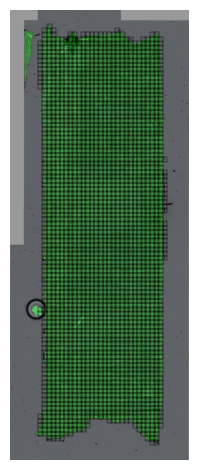

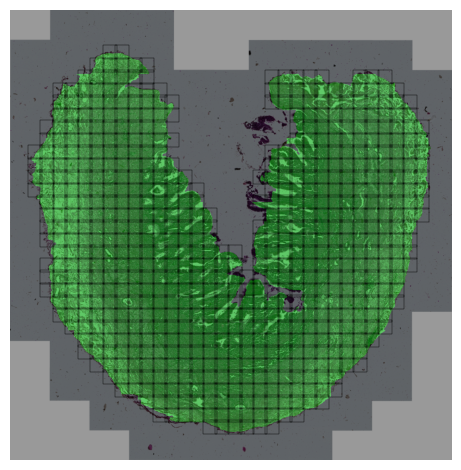

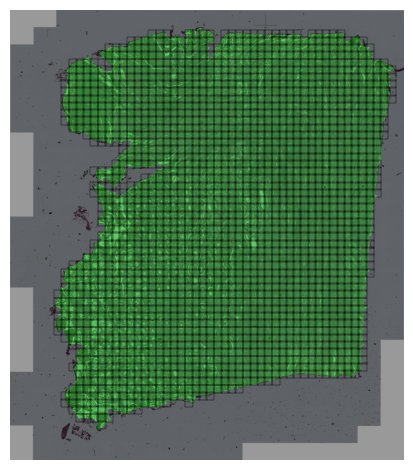

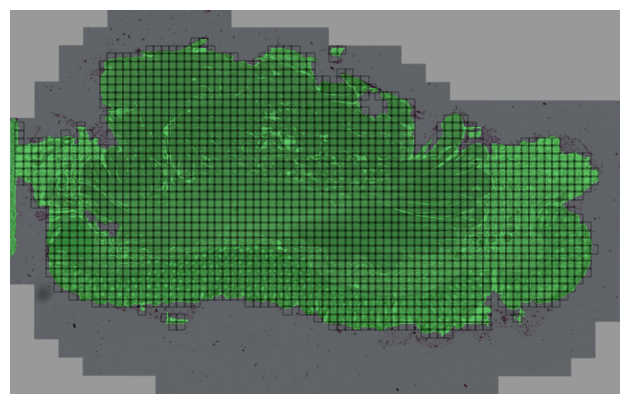

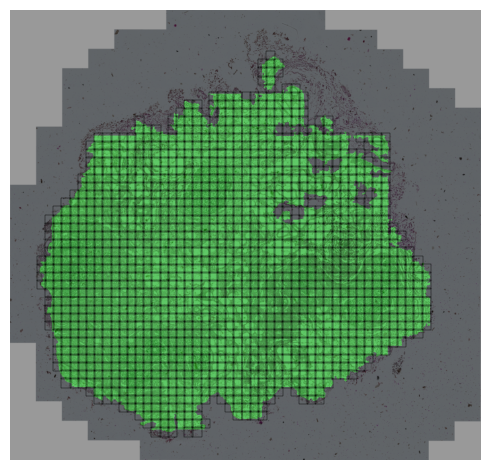

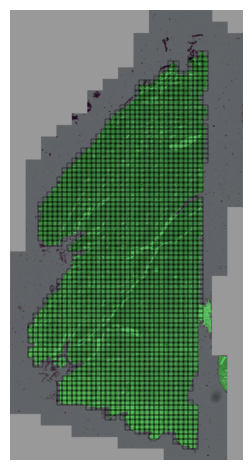

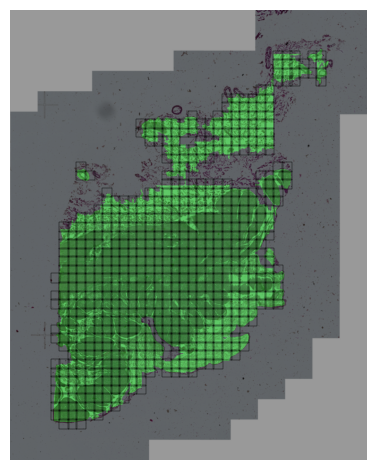

In [ ]:
patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR3/slide1/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

# XeniumPR4
### patching at 0.5 um/px (20x mag, patch size = 112 um, spot size = 100 um)

In [6]:
import ipy_slurm_exec
%load_ext ipy_slurm_exec

The ipy_slurm_exec extension is already loaded. To reload it, use:
  %reload_ext ipy_slurm_exec


In [3]:
%%slurm_exec --partition=gpu --gpus=1 --time=00:10:00 --mem=5G --cpus-per-task=20
import dask
import hest
print(hest.__version__)
from hest.HESTData import read_HESTData
from hest import iter_hest
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd
import math

import scanpy as sc

# cutomised function
from hest.patching_wrapper import *

patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR4/slide1/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR4/slide2/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

Submitted Slurm job 4505394 (folder: slurm_exec/20251117T1753-280fe086)
Job completed                                                                   
Imported variables: Path, Rectangle, count_patches, iter_hest, load_hest_sample, patch_hest_samples, read_HESTData, show_images, …
Resource efficiency:
    JobID    State       Elapsed  TimeEff   CPUEff   MemEff 
  4505394  COMPLETED    00:06:03   60.5%     4.3%    19.5%


# XeniumPR5 (roi 1 - 5)
### patching at 0.5 um/px (20x mag, patch size = 112 um, spot size = 100 um)

In [7]:
%%slurm_exec --partition=gpu --gpus=1 --time=00:10:00 --mem=5G --cpus-per-task=20
import dask
import hest
print(hest.__version__)
from hest.HESTData import read_HESTData
from hest import iter_hest
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd
import math

import scanpy as sc

# cutomised function
from hest.patching_wrapper import *

patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR5/slide1/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

Submitted Slurm job 4568026 (folder: slurm_exec/20251121T1630-4915cd32)
Job completed                                                                   
Imported variables: Path, Rectangle, count_patches, iter_hest, load_hest_sample, patch_hest_samples, read_HESTData, show_images, …
Resource efficiency:
    JobID    State       Elapsed  TimeEff   CPUEff   MemEff 
  4568026  COMPLETED    00:02:51   28.5%     4.1%    16.8%


In [8]:
%%slurm_exec --partition=gpu --gpus=1 --time=00:10:00 --mem=5G --cpus-per-task=20
import dask
import hest
print(hest.__version__)
from hest.HESTData import read_HESTData
from hest import iter_hest
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd
import math

import scanpy as sc

# cutomised function
from hest.patching_wrapper import *

patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumPR5/slide2/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

Submitted Slurm job 4568141 (folder: slurm_exec/20251121T1633-84f5db98)
Job completed                                                                   
Imported variables: Path, Rectangle, count_patches, iter_hest, load_hest_sample, patch_hest_samples, read_HESTData, show_images, …
Resource efficiency:
    JobID    State       Elapsed  TimeEff   CPUEff   MemEff 
  4568141  COMPLETED    00:02:27   24.5%     4.8%    16.4%


Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumPR4/slide1...


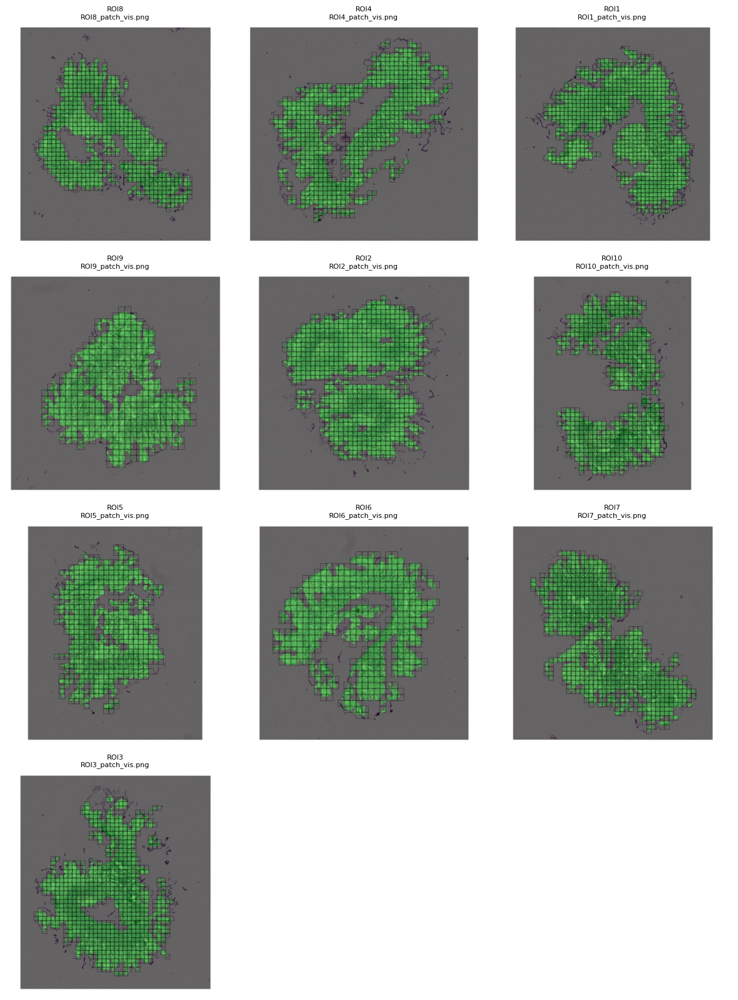

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumPR4/slide1/patches_vis.png
Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumPR4/slide2...


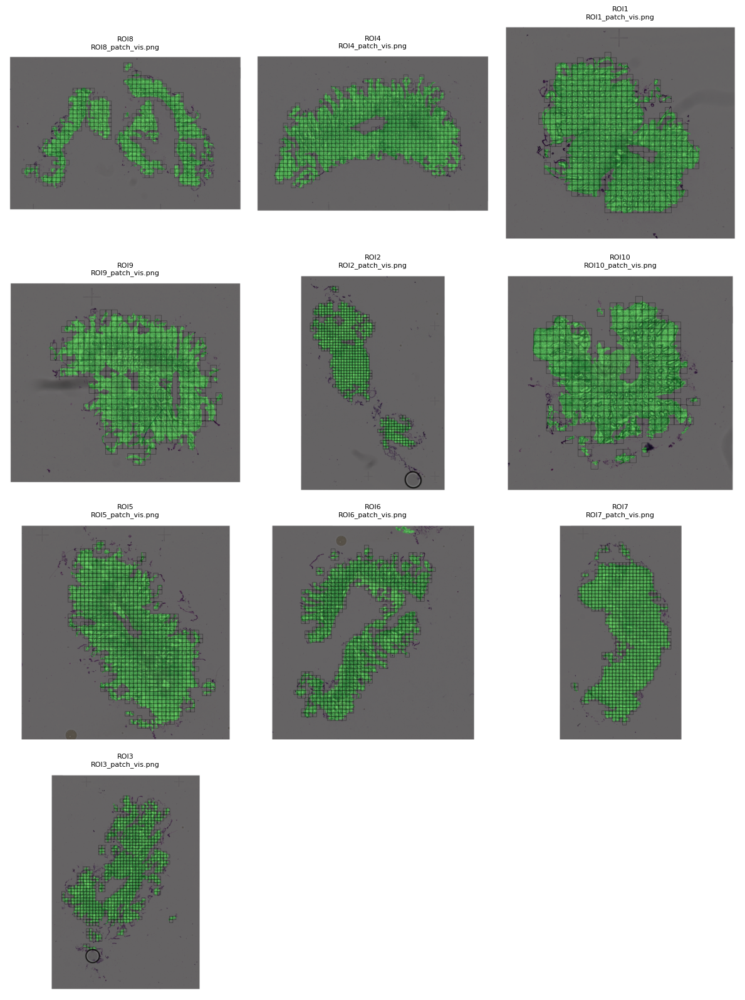

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumPR4/slide2/patches_vis.png
Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumPR5/slide1...


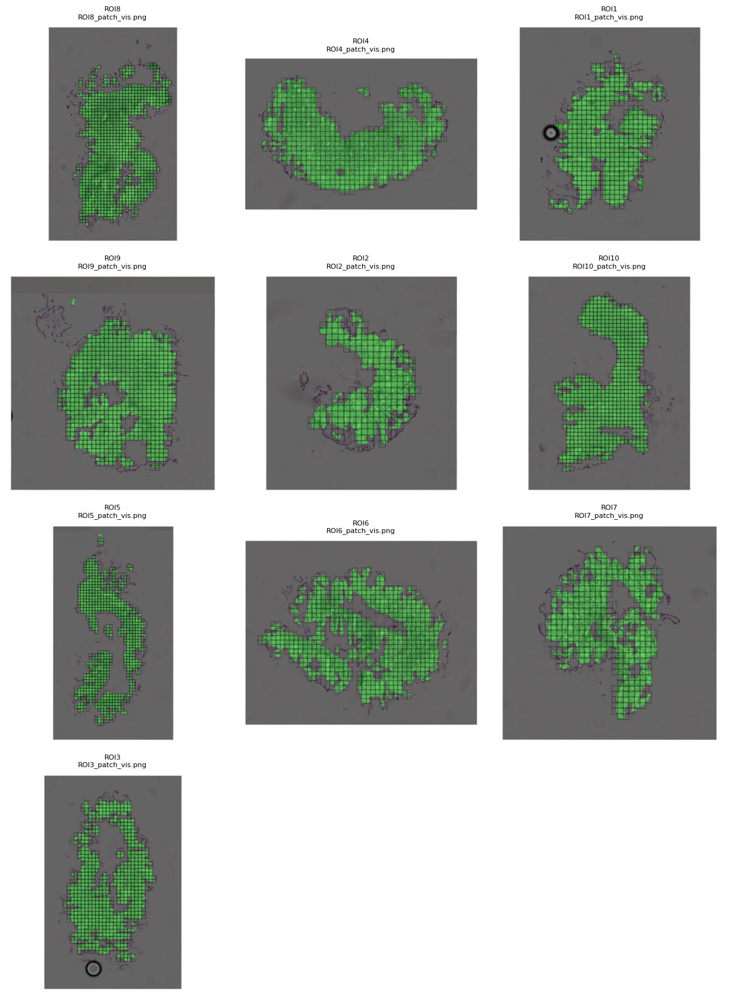

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumPR5/slide1/patches_vis.png
Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumPR5/slide2...


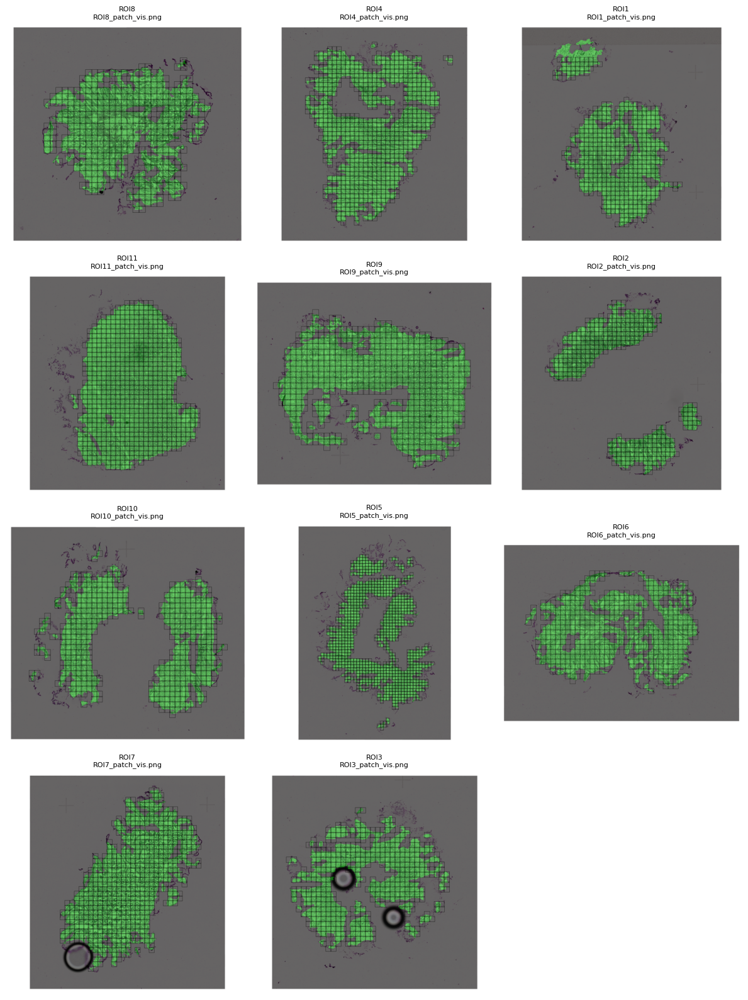

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumPR5/slide2/patches_vis.png


In [9]:
# loop over XeniumR1 to XeniumR6
for i in range(4, 6):
    base = Path(f"/project/simmons_hts/kxu/hest/xenium_data/XeniumPR{i}")
    
    # check both possible subfolders
    for slide in ["slide1", "slide2"]:
        slide_path = base / slide
        if slide_path.exists():
            print(f"Visualise {slide_path}...")
            show_images(broad_dir=slide_path, 
                        subfolders=("patches_vis",),
                        save_dir=slide_path,
                        save_name='patches_vis.png')
        else:
            print(f"Skipping {slide_path} (not found)")

# Xenium 480 Panel

[INFO] Auto-detected 5 sample folders: ['ROI2', 'ROI3', 'ROI4', 'ROI5', 'ROI7']


/home/k/kxu/.local/lib/python3.11/site-packages/hestcore/wsi.py:27: UserWarning: CuImage is not available. Ensure you have a GPU and cucim installed to use GPU acceleration.
  warnings.warn("CuImage is not available. Ensure you have a GPU and cucim installed to use GPU acceleration.")


        'pixel_size' is 0.2206063377139358
        'wsi' is <width=26141, height=23258, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI2: tissue_seg present = True


/home/k/kxu/.local/lib/python3.11/site-packages/hest/HESTData.py:335: UserWarning: Filtered 259 spots outside the WSI
  warnings.warn(f"Filtered {len_tmp - len(coords_topleft)} spots outside the WSI")
100%|██████████| 1145/1145 [00:23<00:00, 48.08it/s]


found 0 valid patches
[INFO] Patches saved for ROI2: /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1/ROI2/patches/ROI2.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1/ROI2/patches_vis/ROI2_patch_vis.png
        'pixel_size' is 0.2203145462360508
        'wsi' is <width=11477, height=10270, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI3: tissue_seg present = True


100%|██████████| 11/11 [00:00<00:00, 22.44it/s]


found 0 valid patches
[INFO] Patches saved for ROI3: /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1/ROI3/patches/ROI3.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1/ROI3/patches_vis/ROI3_patch_vis.png


/package/python-cbrg/current/3.11.11/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:426: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


        'pixel_size' is 0.22035058607882274
        'wsi' is <width=38817, height=29960, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI4: tissue_seg present = True


100%|██████████| 3816/3816 [01:20<00:00, 47.38it/s]


found 0 valid patches
[INFO] Patches saved for ROI4: /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1/ROI4/patches/ROI4.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1/ROI4/patches_vis/ROI4_patch_vis.png
        'pixel_size' is 0.22037675446442723
        'wsi' is <width=28418, height=24464, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI5: tissue_seg present = True


100%|██████████| 1200/1200 [00:21<00:00, 54.95it/s]


found 0 valid patches
[INFO] Patches saved for ROI5: /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1/ROI5/patches/ROI5.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1/ROI5/patches_vis/ROI5_patch_vis.png
        'pixel_size' is 0.22041049001605853
        'wsi' is <width=26706, height=24133, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI7: tissue_seg present = True


100%|██████████| 1336/1336 [00:27<00:00, 48.05it/s]


found 0 valid patches
[INFO] Patches saved for ROI7: /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1/ROI7/patches/ROI7.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1/ROI7/patches_vis/ROI7_patch_vis.png


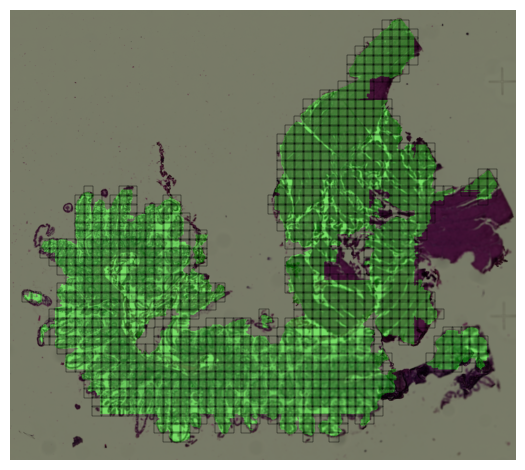

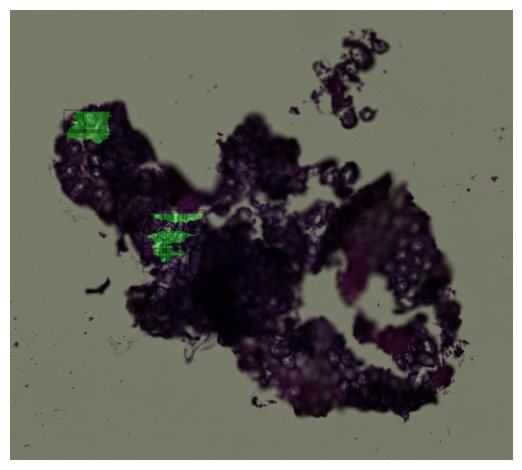

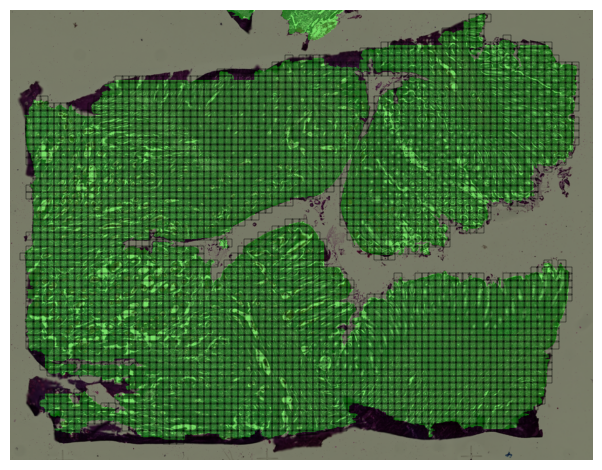

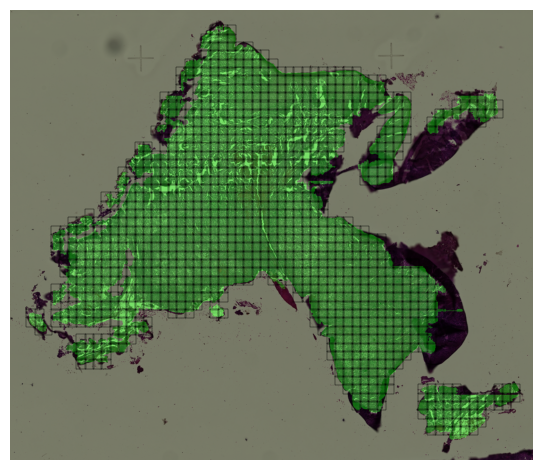

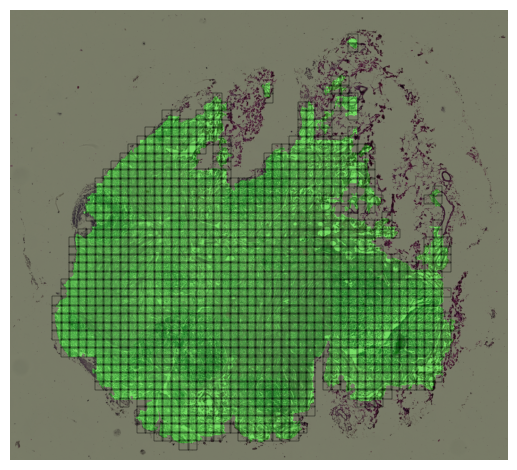

In [2]:
patch_hest_samples(
    broad_root= Path("/project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1/"),
    ids=None,
    target_patch_size = 224,
    target_pixel_size = 0.5,
    threshold = 0.15
)

### run on clusters

In [3]:
import ipy_slurm_exec
%load_ext ipy_slurm_exec

In [7]:
%%slurm_exec --partition=short --cpus=40 --time=00:30:00
from pathlib import Path
import dask
import hest
print(hest.__version__)
from hest.HESTData import read_HESTData
from hest import iter_hest
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd
import math

import scanpy as sc

# cutomised function
from hest.patching_wrapper import *

# loop over XeniumR1 to XeniumR6
for i in range(1, 7):
    base = Path(f"/project/simmons_hts/kxu/hest/xenium_data/XeniumR{i}")
    
    # check both possible subfolders
    for slide in ["slide1", "slide2"]:
        slide_path = base / slide
        if slide_path.exists():
            print(f"Processing {slide_path}...")
            patch_hest_samples(
                broad_root=slide_path,
                ids=None,
                target_patch_size=224,
                target_pixel_size=0.5,
                threshold=0.15,
            )
        else:
            print(f"Skipping {slide_path} (not found)")

Submitted Slurm job 4465255 (folder: slurm_exec/20251110T1411-ef0a076a)
Job 4465255 status: RUNNING (checked 14:20:49)                                  

KeyboardInterrupt: 

### visualise

Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1...


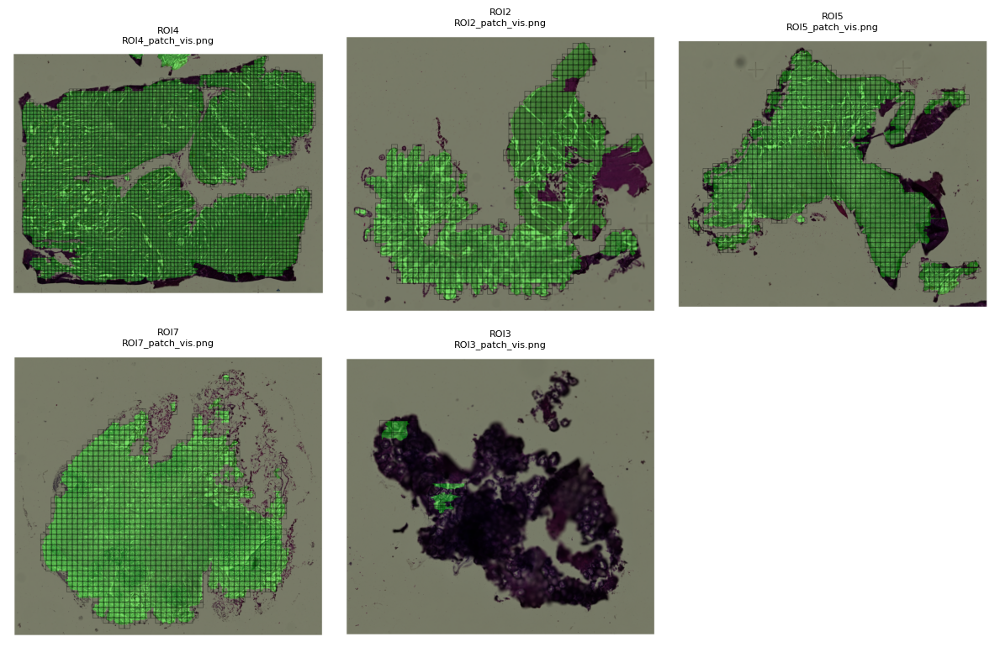

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide1/patches_vis.png
Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide2...


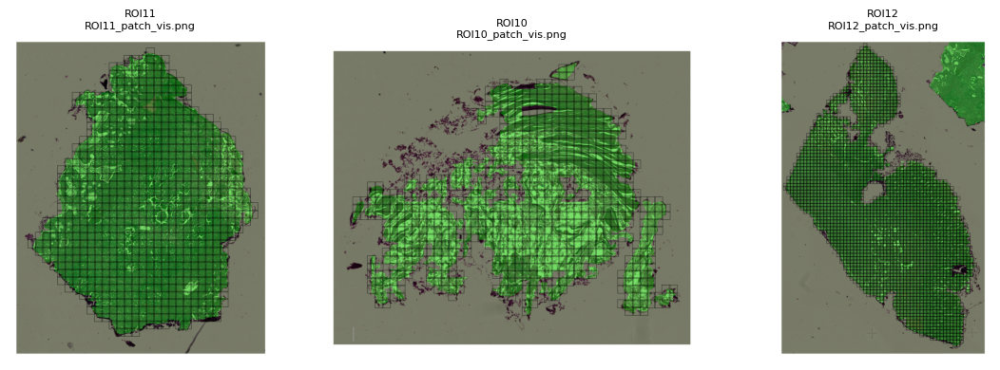

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumR1/slide2/patches_vis.png
Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumR2/slide1...


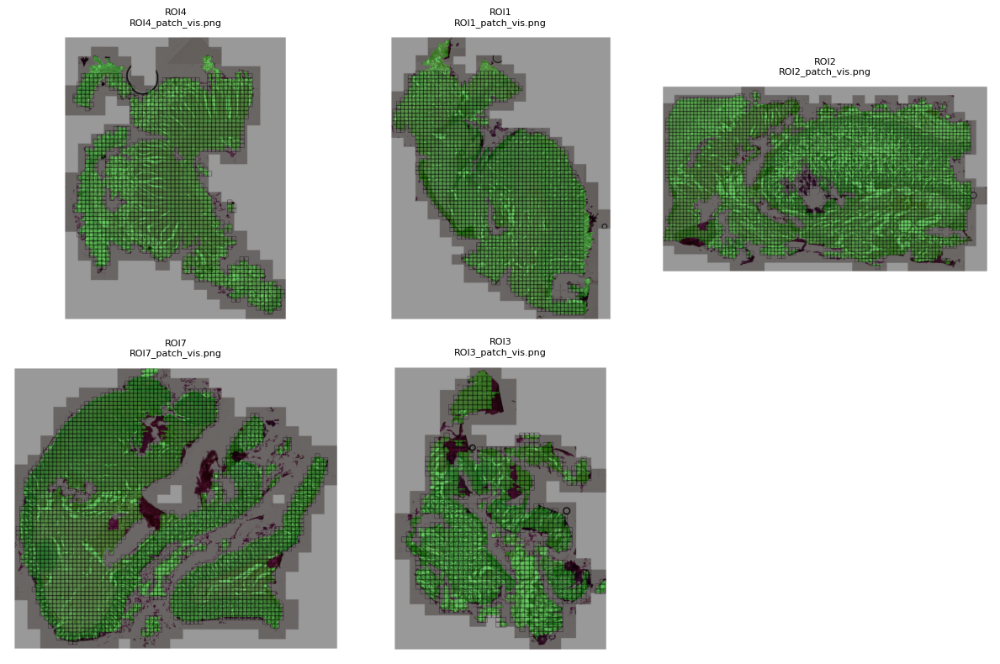

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumR2/slide1/patches_vis.png
Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumR2/slide2...


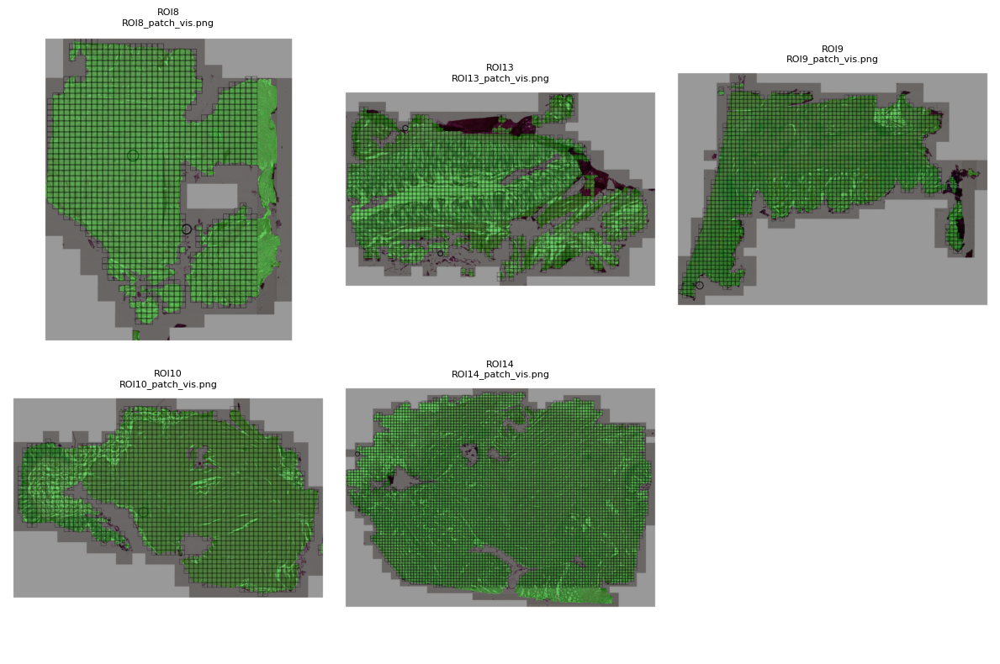

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumR2/slide2/patches_vis.png
Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumR3/slide1...


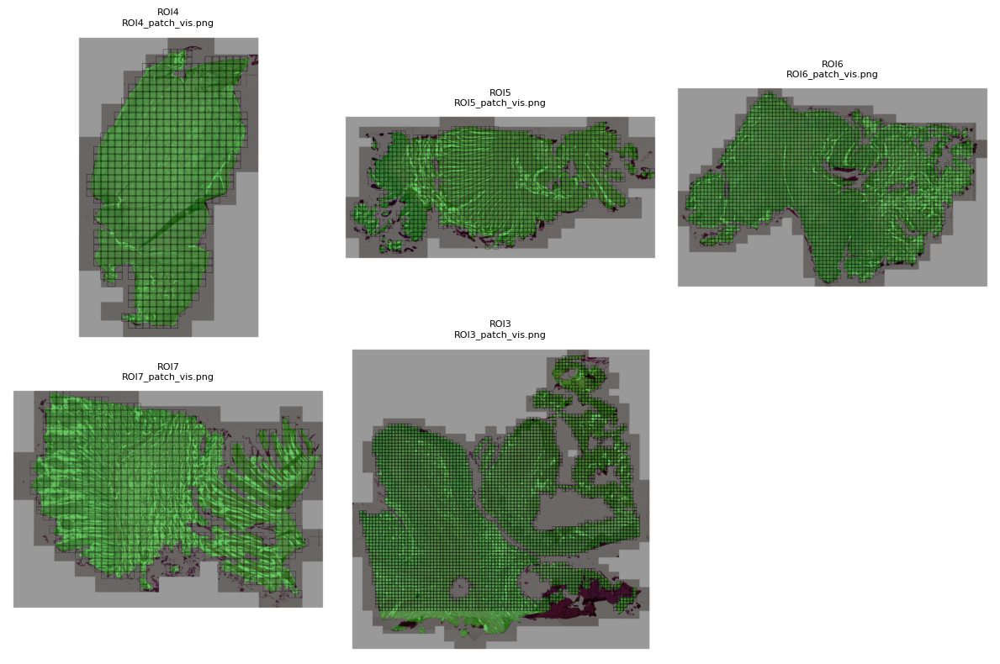

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumR3/slide1/patches_vis.png
Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumR3/slide2...


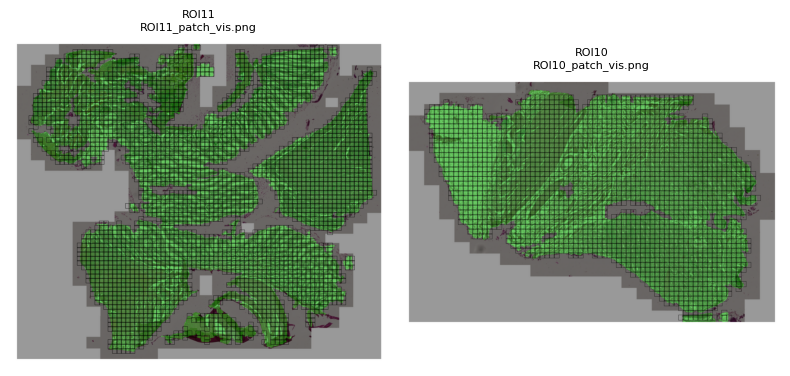

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumR3/slide2/patches_vis.png
Skipping /project/simmons_hts/kxu/hest/xenium_data/XeniumR4/slide1 (not found)
Skipping /project/simmons_hts/kxu/hest/xenium_data/XeniumR4/slide2 (not found)
Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumR5/slide1...


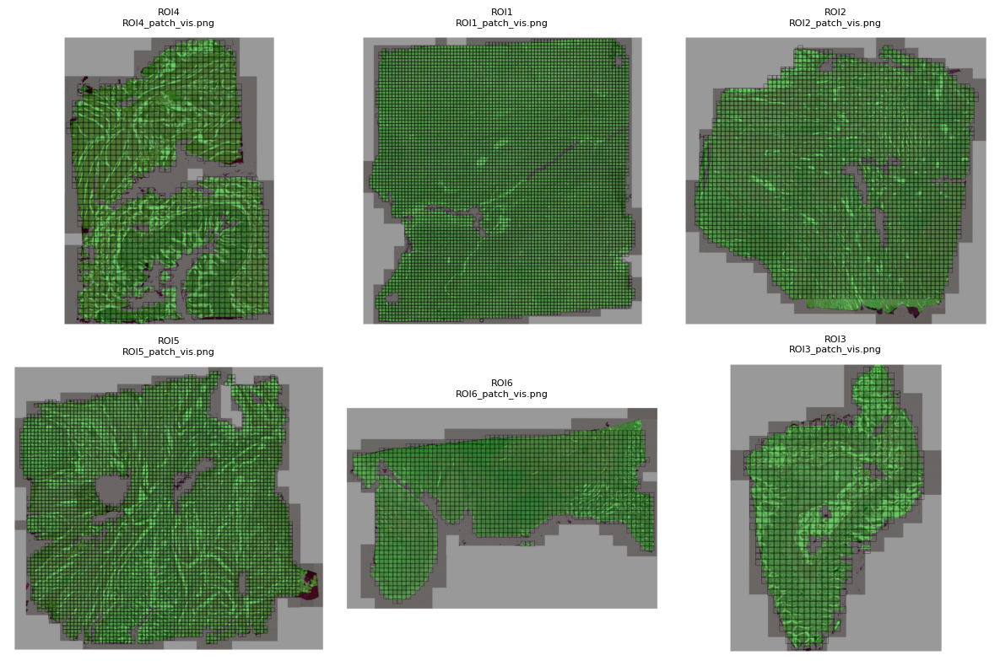

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumR5/slide1/patches_vis.png
Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumR5/slide2...


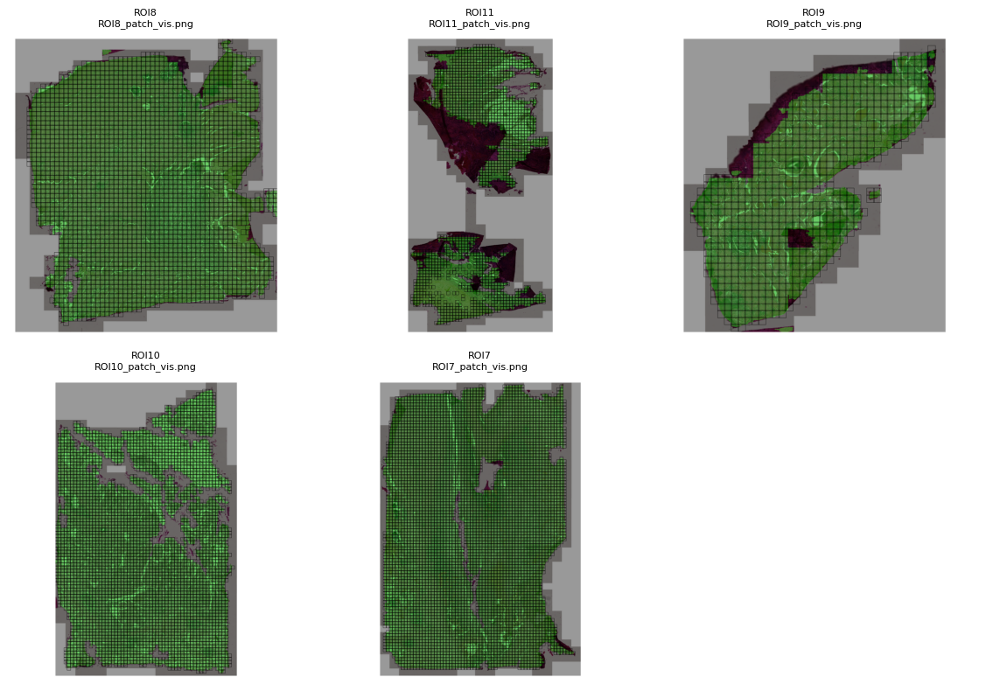

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumR5/slide2/patches_vis.png
Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumR6/slide1...


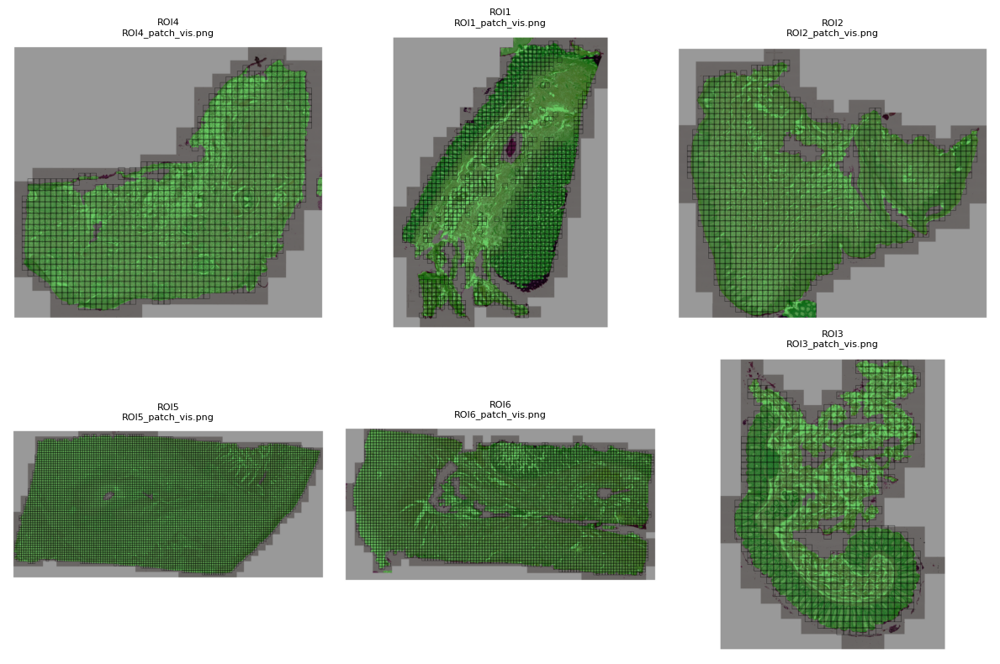

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumR6/slide1/patches_vis.png
Visualise /project/simmons_hts/kxu/hest/xenium_data/XeniumR6/slide2...


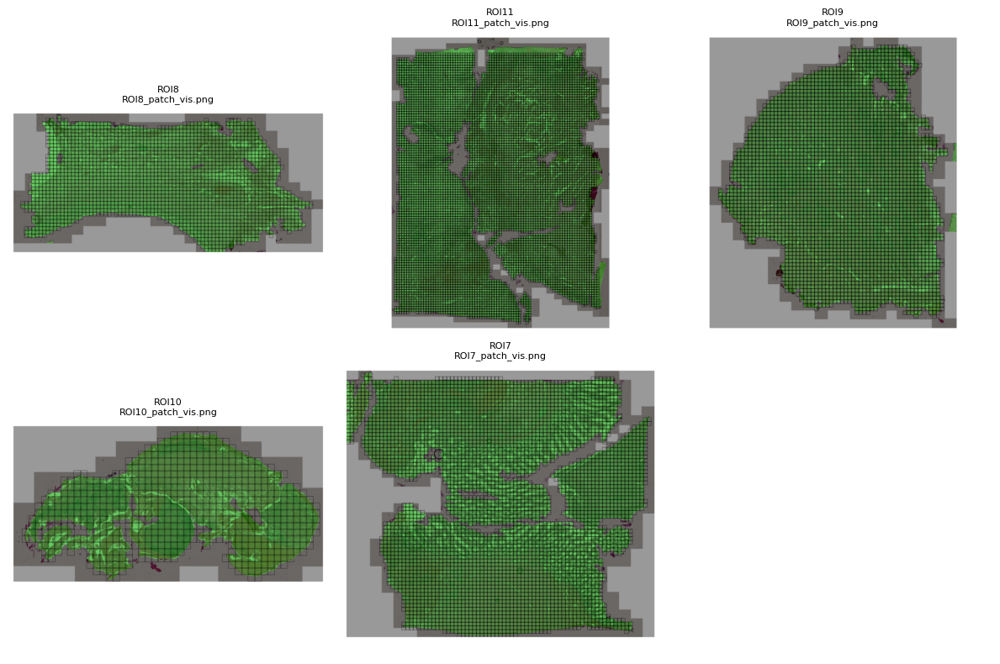

✅ Saved figure to /project/simmons_hts/kxu/hest/xenium_data/XeniumR6/slide2/patches_vis.png


In [2]:
# loop over XeniumR1 to XeniumR6
for i in range(1, 7):
    base = Path(f"/project/simmons_hts/kxu/hest/xenium_data/XeniumR{i}")
    
    # check both possible subfolders
    for slide in ["slide1", "slide2"]:
        slide_path = base / slide
        if slide_path.exists():
            print(f"Visualise {slide_path}...")
            show_images(broad_dir=slide_path, 
                        subfolders=("patches_vis",),
                        save_dir=slide_path,
                        save_name='patches_vis.png')
        else:
            print(f"Skipping {slide_path} (not found)")

# Visium

In [4]:
import ipy_slurm_exec
%load_ext ipy_slurm_exec

In [9]:
%%slurm_exec --partition=gpu --gpus=1 --time=00:30:00 --mem=5G --cpus-per-task=30
from pathlib import Path
import dask
import hest
print(hest.__version__)
from hest.HESTData import read_HESTData
from hest import iter_hest
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd
import math

import scanpy as sc

from hest.patching_wrapper import *

for i in range(6, 7):
    base = Path(f"/project/simmons_hts/kxu/hest/visium_data/VisiumR{i}")
    
    # check both possible subfolders
    for slide in ["slide1", "slide2"]:
        slide_path = base / slide
        if slide_path.exists():
            print(f"Processing {slide_path}...")
            patch_hest_samples(
                broad_root=slide_path,
                ids=None,
                target_patch_size=224,
                target_pixel_size=0.5,
                threshold=0.15,
            )
        else:
            print(f"Skipping {slide_path} (not found)")

Submitted Slurm job 4613700 (folder: slurm_exec/20251202T1843-17421571)
Job 4613700 status: RUNNING (checked 18:44:29)                                  0.0.1
Processing /project/simmons_hts/kxu/hest/visium_data/VisiumR6/slide1...
[INFO] Auto-detected 4 sample folders: ['ROI1', 'ROI2', 'ROI3', 'ROI4']
        'pixel_size' is 0.44247486810664965
        'wsi' is <width=18902, height=18496, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI1: tissue_seg present = True
Job 4613700 status: RUNNING (checked 18:45:09)                                  found 0 valid patches
[INFO] Patches saved for ROI1: /project/simmons_hts/kxu/hest/visium_data/VisiumR6/slide1/ROI1/patches/ROI1.h5
[INFO] Patch visualization saved: /project/simmons_hts/kxu/hest/visium_data/VisiumR6/slide1/ROI1/patches_vis/ROI1_patch_vis.png
        'pixel_size' is 0.44270579640485225
        'wsi' is <width=20345, height=18496, backend=OpenSlideWSI>
        'shapes': []
[INFO] ROI2: tissue_seg present = True
Job 4613700 stat

      |                                                                     |   
  3.5 |-+                                                                 +-|   
      |                                                                     |   
    3 |-+                                                                 +-|   
      |                                                                     |   
  2.5 |-+                                                                 +-|   
      |                                                                     |   
      |                                                                     |   
    2 |-+                                                                 +-|   
      |                                                                     |   
  1.5 |-+                                                                 +-|   
      |                                                                     |   
    1 |-+                   